# 🏗️🛰️ Building Age Classification from Landsat Time Series
## Zimbabwean Astronomical Society — Data Science Regional Hackathon · Final team notebook · ⚡ GPU edition (NVIDIA)

**Task:** classify each 30 m Landsat pixel into one of 4 building-age classes, train on **Madrid**, and transfer to **Amsterdam** with only **n = 5, 25, 50, 100, 200 labelled pixels per class**.

This single notebook runs **end to end from the two raw parquet files** and contains every stage of our solution with an explanation for the judges:

| Part | Stage |
|---|---|
| 0 | Executive summary · challenge · our strategy · jargon |
| 1 | Setup, compute environment, progress logging |
| 2 | Data understanding |
| 3 | Data cleaning and the yearly composite |
| 4 | Labels and class imbalance |
| 5 | Feature engineering — every additional feature, why, and how it helps |
| 6 | Feature sets, per-city scaling and model-specific preprocessing |
| 7 | **Stage 1 — Madrid:** Random Forest first, then other algorithms; comparison |
| 8 | **Stage 2 — Amsterdam transfer:** zero-shot fixes and few-shot methods |
| 9 | **Required results:** Madrid F1 + Amsterdam F1 at 5 sample sizes, F1 vs log₂(n) |
| 10 | What worked, what did not |
| 11 | Deliverables: saved models, `adapt_to_city()`, abstract and written justification |

> Companion notebooks with deeper exploration: `00-Our_Data_Explained.ipynb` (data audit) and `01-Our_Features.ipynb` (feature ablation).

---
# Part 0 — Executive summary

**Results at a glance** (macro F1, mean ± std; final run on an NVIDIA RTX 4060):

| Setting | **Our result** | Starter approach |
|---|---|---|
| Madrid — spatial-block 5-fold CV (honest) | **0.652 ± 0.026** | 0.587 (starter features, same protocol) |
| Madrid — random 5-fold CV (standard) | 0.736 ± 0.003 | ≈ 0.62 (starter RF, random CV) |
| Amsterdam zero-shot (no labels) | **0.624** | 0.343 (starter RF) |
| Amsterdam n = 5 per class | **0.654 ± 0.022** | 0.518 ± 0.040 |
| Amsterdam **n = 25** per class (low-data prize) | **0.687 ± 0.020** | 0.607 ± 0.016 |
| Amsterdam n = 50 per class | 0.723 ± 0.004 | 0.620 ± 0.009 |
| Amsterdam n = 100 per class | 0.740 ± 0.004 | 0.630 ± 0.010 |
| Amsterdam n = 200 per class (peak) | **0.757 ± 0.002** | 0.631 ± 0.008 |
| **Average over the 5 Amsterdam models** | **0.712** | 0.601 |

*Starter column for Amsterdam = the starter notebook's prototype transfer, re-run on exactly the same draws inside this notebook.* The optional label-propagation variant scores slightly higher (n = 25: 0.690, n = 200: 0.761, average 0.716). An independent CPU run of the same pipeline agreed within ±0.003.

**In one sentence:** cleaner inputs, features that describe *age patterns* rather than *city brightness*, per-city scaling and transfer methods that reuse both Madrid's knowledge and Amsterdam's unlabelled pixels beat the starter by **+0.08 to +0.14 macro F1 at every sample size** — with only 5 labels per class Amsterdam already matches Madrid's own cross-validated score.

## The challenge in one picture

```
 MADRID (76 263 labelled pixels)                         AMSTERDAM (25 992 pixels)
 ┌────────────────────────────┐                         ┌──────────────────────────────────┐
 │ 42 years × 6 bands / pixel │ ─ Stage 1: train ─▶ MODEL ─ Stage 2: adapt with n labels ─▶ │ predict age class 1–4 │
 └────────────────────────────┘     (CV: F1 ± std)          n = 5, 25, 50, 100, 200 / class   └──────────────────────────────────┘
                                                             (CV: F1 ± std per n)
```

| Class | Madrid | Amsterdam |
|---|---|---|
| 1 | ≤ 1960 | ≤ 1945 |
| 2 | 1960 – 1984 | 1945 – 1984 |
| 3 | 1984 – 2004 | 1984 – 2004 |
| 4 | 2004 – 2024 | 2004 – 2024 |

**Metric:** macro F1 (each class counts equally). **Prizes:** best average Amsterdam F1, best peak F1, best F1 at n = 25 (low-data), originality.

## Our strategy

1. **Clean better than the starter:** drop broken scenes, saturated and impossible values; build one value per year from the **median of all clean warm-season photos** instead of the first photo (−40 to −46 % year-to-year noise).
2. **Features that describe *age patterns*, not *city brightness*:** spectral indices, robust trends, time windows, **construction change-points** (one- and two-break fits, steepest vegetation-to-built transition), relative (pixel-vs-itself) features, quality, and spatial context.
3. **Per-city standardisation:** each city is scaled with its own statistics — the largest label-free transfer gain we found.
4. **Stage 1:** Random Forest baseline, then Logistic Regression, MLP, LightGBM, XGBoost, CatBoost — each with its own preprocessing — compared under **honest spatial cross-validation**.
5. **Stage 2:** transfer methods that **actually use the Madrid model** (recalibration, fine-tuning with weighted Amsterdam samples, self-training on unlabelled Amsterdam pixels), an **ensemble**, a **class-prior correction** applied only when there are enough labels (n ≥ 25), and **spatial smoothing** of probabilities.
6. **Research-driven upgrades, tested before adoption** (`02-Experiments.ipynb`, same 10 draws per n): we adopted the *safe* prior-correction rule (Alexandari et al., ICML 2020) and two-break change features (BATSCCD 2024); we tested and rejected CORAL alignment, BCTS calibration for zero-shot and iterative self-training; TabPFN v2 (*Nature* 2025) gave +0.003 — inside the error bars — and is left out for reproducibility.

## Jargon used in this notebook

| Term | Meaning |
|---|---|
| **Pixel** | One 30 m × 30 m square of ground. One sample. |
| **Band / reflectance** | One "colour" measured by Landsat (Blue, Green, Red, NIR, SWIR1, SWIR2) and how much light the surface reflects in it. |
| **Index** | A ratio of bands (e.g. NDVI = vegetation). Cancels overall brightness. |
| **Scene** | One satellite photo on one date. |
| **QA bits** | Quality code per pixel per photo: cloud, shadow, snow, water, clear … |
| **Composite** | One value per pixel per year summarising several photos (we use the median). |
| **Time series** | A pixel's 42 yearly values (1984–2025). |
| **Change-point** | The year a series jumps to a new level — usually construction. |
| **Spatial context** | Information from the neighbouring pixels. |
| **Per-city standardisation** | Scale every feature to mean 0 / std 1 within each city — uses no labels. |
| **Domain shift** | The new city's data look different (Amsterdam is darker and greener). |
| **Prior shift** | The new city has a different class mix (more class 1, less class 4 in Amsterdam). |
| **Spatial-block CV** | Cross-validation holding out whole 2 km × 2 km blocks, so near-identical neighbours cannot leak between training and test. |
| **Zero-shot** | Madrid model applied to Amsterdam with no Amsterdam labels. |
| **Few-shot / support / query** | Adapting with n labelled pixels per class (support set); scoring on all other pixels (query set). |
| **Macro F1** | Average of the 4 per-class F1 scores. |
| **OOF (out-of-fold)** | Predictions for each pixel made by the CV model that did *not* train on it. |

---
# Part 1 — Setup and compute environment

**Compute — GPU edition.** Same method as the CPU notebook, but the heavy models run on an **NVIDIA GPU** (developed for an RTX 4060 laptop):

| Model | Device in this notebook |
|---|---|
| XGBoost | **GPU** (`device='cuda'`) |
| CatBoost | **GPU** (`task_type='GPU'`) |
| MLP neural net | **GPU** — PyTorch implementation (same 128-64 architecture, weighted loss, early stopping) |
| LightGBM, Random Forest, Logistic Regression | CPU, all threads (already fast; their GPU builds are not faster at this data size) |

Every GPU choice is **auto-detected**: if CUDA or a library's GPU build is missing, that model falls back to the CPU, so the notebook always runs. GPU tree builders are not bit-for-bit deterministic, so scores may differ from the CPU edition in the third decimal.

**Reproducibility:** one global seed (`SEED = 42`); few-shot draws use seeds 0–9. Every stage writes progress to `logs/final_run.log`.

In [1]:
try:
    import torch   # Windows: torch must be imported BEFORE LightGBM/XGBoost/CatBoost, otherwise its DLLs fail to initialise
except Exception:
    pass
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json, time, warnings, os, joblib
import matplotlib.patches as mpatches
from pathlib import Path
from scipy.ndimage import uniform_filter
from scipy.spatial import cKDTree
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score, confusion_matrix, classification_report
import lightgbm as lgb, xgboost as xgb, catboost as cb
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .3,
                     'axes.spines.top': False, 'axes.spines.right': False})

DATA_DIR = next(Path(p) for p in ['data', '../data', '.'] if (Path(p) / 'madrid_train.parquet').exists())   # repo: put the parquet files in data/
OUT_DIR  = DATA_DIR / 'submission'; OUT_DIR.mkdir(exist_ok=True)
LOG      = DATA_DIR / 'logs' / 'final_run.log'; LOG.parent.mkdir(exist_ok=True); LOG.write_text('')
SEED, N_JOBS = 42, os.cpu_count()

# ── GPU detection (falls back to CPU automatically) ──────────────────────────
import subprocess
def _nvidia():
    try:
        return subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                              capture_output=True, text=True, timeout=20).stdout.strip()
    except Exception:
        return ''
GPU_NAME = _nvidia()
_Xt, _yt = np.random.rand(200, 5), np.random.randint(0, 4, 200)
XGB_DEVICE = 'cpu'
if GPU_NAME:
    try:
        xgb.XGBClassifier(n_estimators=3, device='cuda', tree_method='hist').fit(_Xt, _yt); XGB_DEVICE = 'cuda'
    except Exception as e:
        print('XGBoost GPU unavailable ->', e)
CAT_TASK = 'CPU'
if GPU_NAME:
    try:
        cb.CatBoostClassifier(iterations=3, task_type='GPU', verbose=0).fit(_Xt, _yt); CAT_TASK = 'GPU'
    except Exception as e:
        print('CatBoost GPU unavailable ->', e)
try:
    import torch, torch.nn as nn, torch.nn.functional as Fnn
    TORCH_DEV = 'cuda' if torch.cuda.is_available() else None
except Exception:
    TORCH_DEV = None

CITIES  = ['Madrid', 'Amsterdam']
RAW_FILES = {'Madrid': 'madrid_train.parquet', 'Amsterdam': 'amsterdam_data.parquet'}
BANDS   = ['Blue', 'Green', 'Red', 'NIR', 'SWIR1', 'SWIR2']
SLOTS   = [1, 2, 3]
PID     = ['px_key', 'py_key']
YEARS   = np.arange(1984, 2026); EARLY = YEARS <= 2003; LATE = YEARS >= 2004
CLASSES = np.array([1, 2, 3, 4])
CLASS_EVENTS = {'Madrid': 1960, 'Amsterdam': 1945}
CLASS_COLORS = {1: '#4393c3', 2: '#2ca25f', 3: '#fd8d3c', 4: '#de2d26'}
CITY_COLORS  = {'Madrid': '#c0392b', 'Amsterdam': '#2c6fbb'}
N_SHOTS = [5, 25, 50, 100, 200]; N_DRAWS = 10
SMOKE = os.environ.get('SMOKE') == '1'      # quick test mode: 15 % of pixels, 1 draw per n (never used for reported results)
if SMOKE: N_DRAWS = 1

def log(msg):
    s = f"[{time.strftime('%H:%M:%S')}] {msg}"
    print(s, flush=True)
    with open(LOG, 'a', encoding='utf-8') as f: f.write(s + '\n')

def mf1(y_true, y_pred): return f1_score(y_true, y_pred, average='macro')
log(f"Setup complete — {os.cpu_count()} CPU threads, LightGBM {lgb.__version__}, XGBoost {xgb.__version__}, CatBoost {cb.__version__}")
log(f"GPU: {GPU_NAME or 'none found'} | XGBoost -> {XGB_DEVICE} | CatBoost -> {CAT_TASK} | MLP -> {'PyTorch ' + TORCH_DEV if TORCH_DEV else 'scikit-learn CPU'}")

[07:27:00] Setup complete — 24 CPU threads, LightGBM 4.6.0, XGBoost 3.1.3, CatBoost 1.2.10


[07:27:01] GPU: NVIDIA GeForce RTX 4060, 8188 MiB | XGBoost -> cuda | CatBoost -> GPU | MLP -> PyTorch cuda


---
# Part 2 — Data understanding

**Structure:** one row = **one pixel in one year**; each row stores **up to 3 satellite photos** of that year side by side (`Blue_1 … SWIR2_1`, `_2`, `_3`) with their quality code (`QA_PIXEL`), saturation flag (`QA_RADSAT`), date (`doy`), scene and satellite.

| Column group | Use in our solution |
|---|---|
| `Blue/Green/Red/NIR/SWIR1/SWIR2` × 3 photos | **input** |
| `qa_valid`, `QA_PIXEL`, `QA_RADSAT`, `scene_id` | **cleaning** |
| `doy` (season), `dataset` (satellite) | **control season / sensor effects** |
| `year`, `px_key`, `py_key` | organise time and space; neighbours; CV blocks |
| `weighted_mean_year` | **label** → age class |
| `coverage` | feature + **sample weight** |
| `pixel_x/y`, `row/col`, `usable_label`, `pixel_id`, `city` | dropped (copies of the keys, or constant) |

In [2]:
raw = {c: pd.read_parquet(DATA_DIR / f) for c, f in RAW_FILES.items()}
if SMOKE:
    for c in CITIES:
        keys = raw[c][PID].drop_duplicates().sample(frac=.15, random_state=SEED)
        raw[c] = raw[c].merge(keys, on=PID)
    log('SMOKE TEST MODE — 15 % of pixels')
for c, df in raw.items():
    log(f"{c:10s}: {len(df):,} rows × {df.shape[1]} columns | {df.groupby(PID).ngroups:,} pixels | "
        f"years {df.year.min()}–{df.year.max()} | missing values {int(df.isna().sum().sum())}")
raw['Madrid'].iloc[0].to_frame('example row').T

[07:27:02] Madrid    : 3,172,765 rows × 48 columns | 76,263 pixels | years 1984–2025 | missing values 0


[07:27:02] Amsterdam : 1,062,877 rows × 48 columns | 25,992 pixels | years 1984–2025 | missing values 0


,pixel_id,city,year,px_key,py_key,pixel_x,pixel_y,row,col,coverage,usable_label,weighted_mean_year,Blue_1,Green_1,Red_1,NIR_1,SWIR1_1,SWIR2_1,QA_PIXEL_1,QA_RADSAT_1,...,SWIR1_2,SWIR2_2,QA_PIXEL_2,QA_RADSAT_2,doy_2,scene_id_2,dataset_2,qa_valid_2,Blue_3,Green_3,Red_3,NIR_3,SWIR1_3,SWIR2_3,QA_PIXEL_3,QA_RADSAT_3,doy_3,scene_id_3,dataset_3,qa_valid_3
example row,Madrid_14194_149671_1984,Madrid,1984,14194,149671,425820.0,4490130.0,5,20,0.15,True,2014.0,9184.207031,9821.585938,10537.317383,15736.041016,16615.345703,13306.133789,5440,0,...,16767.910156,13043.585938,5440,0,231,LT05_L2SP_201032_19840818_20200918_02_T1,landsat_tm_c2_l2,True,9323.154297,10433.227539,11603.330078,16555.982422,18056.576172,13991.788086,5440,0,247,LT05_L2SP_201032_19840903_20201008_02_T2,landsat_tm_c2_l2,True


### Key facts from our data audit (`00-Our_Data_Explained.ipynb`)

| # | Finding | Consequence for our pipeline |
|---|---|---|
| 1 | Photos come from **all seasons** (only 50 % Madrid / 31 % Amsterdam in Jun–Aug) | prefer **May–September** photos in the yearly composite |
| 2 | Starter "first clean photo" rule discards ~60 % of clean photos | use the **median of all clean photos** |
| 3 | **3 whole scenes are broken** but pass `qa_valid` | drop them entirely |
| 4 | Amsterdam is cloudy (27 % of photos invalid) | fewer photos per year → robust statistics |
| 5 | Sensor changes over time (Landsat 5 → 7 → 8/9) leave small offsets | medians, ratios, per-city scaling |
| 6 | 2 227 Madrid pixels sit exactly on **1960** (class 1/2 boundary) | noisy boundary — tested in Part 4 |
| 7 | Classes 1–2 labels are mostly **mixtures** of buildings | expected confusion between neighbouring classes |
| 8 | **Prior shift**: Amsterdam has +11 pts class 1, −11 pts class 4 | class-prior correction in Stage 2 |
| 9 | **Domain shift**: Amsterdam darker in every band, greener | per-city scaling, relative features |
| 10 | Strong **spatial autocorrelation** (neighbour has same class 76 % / 87 % of the time) | spatial features, spatial smoothing, **spatial-block CV** |

---
# Part 3 — Cleaning and the yearly composite

### 3.1 One row per photo (long format)
We reshape `_1/_2/_3` into one row per photo and decode the cirrus confidence (bits 14–15 of `QA_PIXEL`) — the organisers' `qa_valid` flag does not check cirrus.

In [3]:
CUM_DAYS = np.array([31, 59, 90, 120, 151, 181, 212, 243, 273, 304, 334])
def to_long(df):
    parts = []
    for s in SLOTS:
        ren = {f'{b}_{s}': b for b in BANDS}
        ren.update({f'QA_PIXEL_{s}': 'QA_PIXEL', f'QA_RADSAT_{s}': 'QA_RADSAT', f'doy_{s}': 'doy',
                    f'scene_id_{s}': 'scene_id', f'qa_valid_{s}': 'qa_valid'})
        parts.append(df[PID + ['year'] + list(ren)].rename(columns=ren))
    o = pd.concat(parts, ignore_index=True)
    o[BANDS] = o[BANDS].astype('float32')
    o['scene_id'] = o.scene_id.astype('category')
    o['month'] = (np.searchsorted(CUM_DAYS, o.doy.to_numpy(), side='left') + 1).astype('int8')
    o['cirrus_conf'] = ((o.QA_PIXEL.to_numpy().astype(np.int64) >> 14) & 3).astype('int8')
    return o

pixels = {}
for c in CITIES:
    p = raw[c].groupby(PID).agg(wmy=('weighted_mean_year', 'first'), coverage=('coverage', 'first')).reset_index()
    pixels[c] = p.sort_values(PID).reset_index(drop=True)
obs = {c: to_long(raw[c]) for c in CITIES}
del raw; import gc; gc.collect()
for c in CITIES: log(f"{c:10s}: {len(obs[c]):,} photo-observations")

[07:27:03] Madrid    : 9,518,295 photo-observations


[07:27:03] Amsterdam : 3,188,631 photo-observations


### 3.2 Broken scenes
Per scene we compute the median Blue of its clean pixels and the share above 15 000. A scene with median Blue > 12 000 or > 5 % of pixels above 15 000 is **broken** (haze, snow, low winter sun or a processing fault) and removed completely.

In [4]:
BAD_SCENES = {}
for c in CITIES:
    v = obs[c][obs[c].qa_valid]
    t = v.groupby('scene_id', observed=True).Blue.agg(median_blue='median', frac_gt15k=lambda x: (x > 15000).mean(), n='size')
    BAD_SCENES[c] = set(t.index[(t.median_blue > 12000) | (t.frac_gt15k > 0.05)])
    log(f"{c:10s}: broken scenes → {sorted(BAD_SCENES[c])}")

[07:27:03] Madrid    : broken scenes → ['LT05_L2SP_201032_19951207_20211123_02_T2']


[07:27:04] Amsterdam : broken scenes → ['LE07_L2SP_198023_20020417_20200916_02_T2', 'LT05_L2SP_199023_19961109_20211124_02_T1']


### 3.3 Cleaning rules (applied in order)

| Rule | Removes | Why |
|---|---|---|
| R1 | `qa_valid == False` | cloud, shadow, snow, water, no data |
| R2 | broken scene | whole photo wrong |
| R3 | `QA_RADSAT > 0` | saturated — true value unknown |
| R4 | any band = 0 | physically impossible |
| R5 | high-confidence cirrus | thin cloud not covered by `qa_valid` |
| R6 | Blue > 15 000 | safety net for leftover haze |

In [5]:
def clean_obs(o, bad):
    rules = [('R1 not qa_valid', ~o.qa_valid), ('R2 broken scene', o.scene_id.isin(bad)),
             ('R3 saturated', o.QA_RADSAT > 0), ('R4 zero band', (o[BANDS] == 0).any(axis=1)),
             ('R5 cirrus', o.cirrus_conf == 3), ('R6 Blue>15000', o.Blue > 15000)]
    keep = np.ones(len(o), bool); rows = []
    for name, bad_mask in rules:
        rem = (keep & bad_mask.values).sum(); keep &= ~bad_mask.values
        rows.append({'rule': name, 'removed': rem, '% of all': round(rem / len(o) * 100, 2)})
    return o[keep], pd.DataFrame(rows)

clean, tables = {}, []
for c in CITIES:
    clean[c], t = clean_obs(obs[c], BAD_SCENES[c]); tables.append(t.set_index('rule').add_prefix(f'{c} '))
    log(f"{c:10s}: kept {len(clean[c]):,} of {len(obs[c]):,} photo-observations ({len(clean[c])/len(obs[c]):.1%})")
del obs; gc.collect()
pd.concat(tables, axis=1)

[07:27:04] Madrid    : kept 8,800,748 of 9,518,295 photo-observations (92.5%)


[07:27:04] Amsterdam : kept 2,281,625 of 3,188,631 photo-observations (71.6%)


,Madrid removed,Madrid % of all,Amsterdam removed,Amsterdam % of all
rule,,,,
R1 not qa_valid,609794,6.41,873280,27.39
R2 broken scene,4718,0.05,21426,0.67
R3 saturated,13362,0.14,1201,0.04
R4 zero band,78,0.00,18,0.00
R5 cirrus,0,0.00,6,0.00
R6 Blue>15000,89595,0.94,11075,0.35


### 3.4 Yearly composite — one value per pixel per year

**Median of the clean photos from May–September**; if a year has none, the median of all clean photos (`fallback`). The median ignores one odd photo; the warm-season window keeps the season consistent between years. In our audit this cut the typical year-to-year NDVI jump by **46 % (Madrid) and 40 % (Amsterdam)** versus the starter's first-photo rule — real changes (construction) stand out more clearly.

In [6]:
def yearly_composite(cl):
    keys = PID + ['year']; warm = cl.month.between(5, 9)
    all_med  = cl.groupby(keys)[BANDS].median()
    warm_med = cl[warm].groupby(keys)[BANDS].median().reindex(all_med.index)
    use_warm = warm_med.notna().all(axis=1)
    comp = warm_med.where(use_warm, all_med)
    comp['n_photos'] = cl.groupby(keys).size()
    comp['season'] = np.where(use_warm, 'warm', 'fallback')
    return comp.reset_index()

yearly = {}
for c in CITIES:
    yearly[c] = yearly_composite(clean[c])
    log(f"{c:10s}: {len(yearly[c]):,} pixel-years | warm-season {(yearly[c].season == 'warm').mean():.0%}")
del clean; gc.collect()

[07:27:11] Madrid    : 3,147,969 pixel-years | warm-season 97%


[07:27:12] Amsterdam : 1,058,169 pixel-years | warm-season 91%


0

---
# Part 4 — Labels and class imbalance

`weighted_mean_year` (area-weighted mean construction year of the buildings in the pixel) is cut into 4 classes with city-specific boundaries. `pd.cut` includes the right edge: exactly 1960.0 in Madrid → class 1.

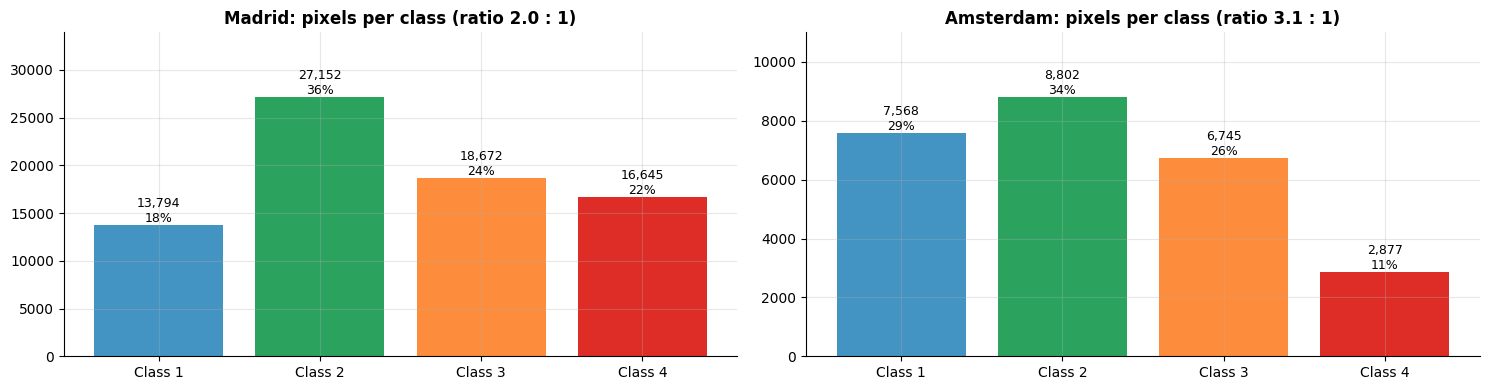

,Madrid,Amsterdam,Madrid %,Amsterdam %
1,13794,7568,18.1,29.1
2,27152,8802,35.6,33.9
3,18672,6745,24.5,26.0
4,16645,2877,21.8,11.1


In [7]:
def assign_class(wmy, city):
    return pd.cut(wmy, [-np.inf, CLASS_EVENTS[city], 1984, 2004, np.inf], labels=[1, 2, 3, 4]).astype(int)

for c in CITIES:
    pixels[c]['age_class'] = assign_class(pixels[c].wmy, c)
y = {c: pixels[c].age_class.to_numpy() for c in CITIES}

counts = pd.DataFrame({c: pd.Series(y[c]).value_counts().sort_index() for c in CITIES})
shares = (counts / counts.sum() * 100).round(1).add_suffix(' %')
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, c in zip(axes, CITIES):
    vc = counts[c]
    bars = ax.bar([f'Class {k}' for k in CLASSES], vc.values, color=[CLASS_COLORS[k] for k in CLASSES])
    for b, v in zip(bars, vc.values): ax.text(b.get_x() + b.get_width()/2, v, f'{v:,}\n{v/vc.sum():.0%}', ha='center', va='bottom', fontsize=9)
    ax.set_ylim(0, vc.max() * 1.25); ax.set_title(f'{c}: pixels per class (ratio {vc.max()/vc.min():.1f} : 1)', fontweight='bold')
plt.tight_layout(); plt.show()
pd.concat([counts, shares], axis=1)

**Imbalance — our approach:**
- Madrid is moderately imbalanced (2.0 : 1), Amsterdam more (3.1 : 1, small class 4).
- **Training:** every model gets `sample_weight = coverage × balanced-class-weight` (normalised). Balanced weights stop the model favouring class 2; coverage gives pixels that are mostly building — cleaner signal and cleaner label — more say (it gave a small consistent gain in our ablation).
- Because training is balanced, the model's **implicit class prior is uniform**. In Amsterdam we **re-estimate the real class mix from unlabelled pixels** (EM prior correction, Part 8) instead of assuming Madrid's.
- **No synthetic oversampling (SMOTE):** with 2 900 – 27 000 pixels per class it adds little and can create unrealistic time series.

In [8]:
def train_weights(yv, coverage):
    cw = len(yv) / (4 * np.bincount(yv, minlength=5)[1:])
    w = coverage * cw[yv - 1]
    return w / w.mean()
W_MAD = train_weights(y['Madrid'], pixels['Madrid'].coverage.to_numpy())
pd.Series(W_MAD).groupby(y['Madrid']).mean().rename('mean training weight per class').to_frame().T.round(2)

,1,2,3,4
mean training weight per class,1.5,0.71,0.92,1.14


---
# Part 5 — Feature engineering

The challenge says: *"Teams are free (and encouraged) to engineer additional features, apply spatial context, or use any other strategy they see fit."* Below is **every feature group we added**, what it is, **why** it should help and **how** it helped (evidence from our ablation, `01-Our_Features.ipynb`, re-built here end to end).

### 5.1 Data cube
Reshape the yearly composite into a cube **pixels × 42 years** per channel. Two versions: `real` (NaN where a year had no clean photo — used for statistics) and `filled` (gaps linearly interpolated — used only where a complete series is needed: step fits, year-on-year jumps).

In [9]:
def make_cube(yr, pix):
    wide = yr.set_index(PID + ['year'])[BANDS].unstack('year').reindex(pd.MultiIndex.from_frame(pix[PID]))
    cbd = {b: wide[b].reindex(columns=YEARS).to_numpy(np.float32) for b in BANDS}
    return cbd, ~np.isnan(cbd['Blue'])

def fill_gaps(M):
    return pd.DataFrame(M.T).interpolate(limit_direction='both').to_numpy(np.float32).T

cube, mask = {}, {}
for c in CITIES:
    cube[c], mask[c] = make_cube(yearly[c], pixels[c])
    log(f"{c:10s}: cube {mask[c].shape} | real years {mask[c].mean():.1%}")

[07:27:13] Madrid    : cube (76263, 42) | real years 98.3%


[07:27:13] Amsterdam : cube (25992, 42) | real years 96.9%


### 5.2 Spectral indices

| Index | Formula | Captures | Why it helps |
|---|---|---|---|
| NDVI | (NIR−Red)/(NIR+Red) | vegetation | gardens/fields replaced by buildings; old dense centres have none |
| NDBI | (SWIR1−NIR)/(SWIR1+NIR) | built-up | amount and type of built surface |
| UI | (SWIR2−NIR)/(SWIR2+NIR) | urban | urban density |
| MNDWI | (Green−SWIR1)/(Green+SWIR1) | water / moisture | separates materials and wet surfaces |
| BSI | ((SWIR1+Red)−(NIR+Blue))/sum | bare soil | **construction sites** |
| **NBR** (new) | (NIR−SWIR2)/(NIR+SWIR2) | vegetation vs bare | sharper construction signal |
| **NDTI** (new) | (SWIR1−SWIR2)/(SWIR1+SWIR2) | roofing / mineral material | building-material differences |
| **TCB, TCG, TCW** (new) | tasselled cap brightness / greenness / wetness (OLI coefficients, Baig et al. 2014; reflectance = value × 0.0000275 − 0.2) | standard Landsat change axes | used by building-age papers (BATSCCD) |

**Ratios cancel overall brightness** (sun, haze, sensor, city) — key for transferring from bright Madrid to darker Amsterdam.

In [10]:
IDX_STARTER = ['NDVI', 'NDBI', 'UI', 'MNDWI', 'BSI']; IDX_NEW = ['NBR', 'NDTI', 'TCB', 'TCG', 'TCW']
TC = {'TCB': [0.3029, 0.2786, 0.4733, 0.5599, 0.5080, 0.1872],
      'TCG': [-0.2941, -0.2430, -0.5424, 0.7276, 0.0713, -0.1608],
      'TCW': [0.1511, 0.1973, 0.3283, 0.3407, -0.7117, -0.4559]}
def add_indices(cbd):
    B, G, R, N, S1, S2 = (cbd[b] for b in BANDS); e = 1e-6
    cbd['NDVI'] = (N - R) / (N + R + e); cbd['NDBI'] = (S1 - N) / (S1 + N + e); cbd['UI'] = (S2 - N) / (S2 + N + e)
    cbd['MNDWI'] = (G - S1) / (G + S1 + e); cbd['BSI'] = ((S1 + R) - (N + B)) / ((S1 + R) + (N + B) + e)
    cbd['NBR'] = (N - S2) / (N + S2 + e); cbd['NDTI'] = (S1 - S2) / (S1 + S2 + e)
    refl = [cbd[b] * 2.75e-5 - 0.2 for b in BANDS]
    for k, w in TC.items(): cbd[k] = sum(wi * r for wi, r in zip(w, refl)).astype(np.float32)
    return cbd
CHANNELS = BANDS + IDX_STARTER + IDX_NEW
real, filled = {}, {}
for c in CITIES:
    real[c] = add_indices(dict(cube[c])); filled[c] = {ch: fill_gaps(real[c][ch]) for ch in CHANNELS}
log("Indices ready: " + ', '.join(CHANNELS))

[07:27:23] Indices ready: Blue, Green, Red, NIR, SWIR1, SWIR2, NDVI, NDBI, UI, MNDWI, BSI, NBR, NDTI, TCB, TCG, TCW


### 5.3 The feature groups

| Group | Features | What | Why it should help |
|---|---|---|---|
| **S** Starter-like (58) | mean, std of bands + 5 indices; early (≤2003) / late (≥2004) mean & std of bands; mean & std of year-on-year change | the starter's recipe on our cleaner data | baseline; early-vs-late contrast flags classes 3–4 |
| **A** New indices (20) | NBR, NDTI, TCB, TCG, TCW: mean, std, early, late | extra material / vegetation axes | richer description of materials |
| **B** Robust stats & trends (88) | median, IQR, p10, p90, slope, early slope, late slope, volatility for 11 channels | outlier-resistant level, spread and direction | one bad year cannot distort them |
| **C** Time windows (35) | median of 7 six-year windows for 5 channels | *when* the pixel changed | separates construction in 1984–2004 vs after 2004 |
| **D** Change-point (36) | step-fit **year, size, strength** for 7 channels; post-2004 break; biggest single-year jump | construction event | classes 3–4 show a strong break, 1–2 do not — **in any city** |
| **E** Relative (23) | late − early, late ÷ early, band "shape" (band / sum of bands) | pixel compared with itself | cancels city-wide brightness |
| **F** Quality (5) | coverage, % filled years, longest gap, photos per year, % fallback-season years | how much to trust the series | lets the model discount weak series |
| **G** Spatial (34) | leave-self-out neighbourhood means at 90 / 210 / 450 m, building density, local spread, pixel − neighbourhood | the district around the pixel | neighbourhoods are built in the same era |
| **H** Two-break & transition (22) | best **three-level** fit (two break years, two level changes, strength, gain over one break) for NDVI, NDBI, TCB; year and size of the steepest 3-year NDVI drop and NDBI rise | demolition → rebuild, or construction → renovation; the "vegetation → built" transition | added after the research experiments: +0.004 to +0.011 at every n |

All groups are computed **without labels**, by the same code for both cities.

In [11]:
def nmean(M): return np.nanmean(M, 1)
def nstd(M):  return np.nanstd(M, 1, ddof=1)
def nmed(M):  return np.nanmedian(M, 1)
def npct(M, q): return np.nanpercentile(M, q, axis=1)
def masked_slope(R, yrs):
    x = np.where(np.isnan(R), np.nan, yrs[None, :].astype(np.float32))
    xm, ym = np.nanmean(x, 1, keepdims=True), np.nanmean(R, 1, keepdims=True)
    num = np.nansum((x - xm) * (R - ym), 1); den = np.nansum((x - xm) ** 2, 1)
    return np.where(den > 0, num / np.where(den > 0, den, 1), np.nan)
def longest_gap(m):
    run = np.zeros(len(m)); best = np.zeros(len(m))
    for t in range(m.shape[1]): run = (run + 1) * (~m[:, t]); best = np.maximum(best, run)
    return best

def feats_S(R, F):
    out = {}
    for ch in BANDS + IDX_STARTER: out[f'{ch}_mean'] = nmean(R[ch]); out[f'{ch}_std'] = nstd(R[ch])
    for b in BANDS:
        out[f'{b}_early_mean'] = nmean(R[b][:, EARLY]); out[f'{b}_early_std'] = nstd(R[b][:, EARLY])
        out[f'{b}_late_mean'] = nmean(R[b][:, LATE]);   out[f'{b}_late_std'] = nstd(R[b][:, LATE])
        d = np.diff(F[b], axis=1); out[f'd_{b}_mean'] = d.mean(1); out[f'd_{b}_std'] = d.std(1, ddof=1)
    return pd.DataFrame(out)

def feats_A(R, F):
    out = {}
    for ch in IDX_NEW:
        out[f'{ch}_mean'] = nmean(R[ch]); out[f'{ch}_std'] = nstd(R[ch])
        out[f'{ch}_early_mean'] = nmean(R[ch][:, EARLY]); out[f'{ch}_late_mean'] = nmean(R[ch][:, LATE])
    return pd.DataFrame(out)

K = ['NDVI', 'NDBI', 'MNDWI', 'BSI', 'NBR', 'NDTI', 'TCB', 'TCG', 'TCW', 'SWIR1', 'NIR']
def feats_B(R, F):
    out = {}
    for ch in K:
        M = R[ch]; p10, p25, p50, p75, p90 = (npct(M, q) for q in (10, 25, 50, 75, 90))
        out[f'{ch}_med'] = p50; out[f'{ch}_iqr'] = p75 - p25; out[f'{ch}_p10'] = p10; out[f'{ch}_p90'] = p90
        out[f'{ch}_slope'] = masked_slope(M, YEARS)
        out[f'{ch}_slope_early'] = masked_slope(M[:, EARLY], YEARS[EARLY]); out[f'{ch}_slope_late'] = masked_slope(M[:, LATE], YEARS[LATE])
        out[f'{ch}_volatility'] = nmed(np.abs(np.diff(M, axis=1)))
    return pd.DataFrame(out)

WINDOWS = [(1984, 1989), (1990, 1995), (1996, 2001), (2002, 2007), (2008, 2013), (2014, 2019), (2020, 2025)]
def feats_C(R, F):
    out = {}
    for ch in ['NDVI', 'NDBI', 'BSI', 'TCB', 'SWIR1']:
        for a, b in WINDOWS: out[f'{ch}_w{a}'] = nmed(R[ch][:, (YEARS >= a) & (YEARS <= b)])
    return pd.DataFrame(out)

def step_break(Y, yrs):
    T = Y.shape[1]; k = np.arange(1, T)
    cs = np.cumsum(Y, axis=1, dtype=np.float64)[:, :-1]; tot = Y.sum(1, keepdims=True, dtype=np.float64)
    before, after = cs / k, (tot - cs) / (T - k)
    gain = k * (T - k) / T * (after - before) ** 2
    best = gain.argmax(1); i = np.arange(len(Y))
    return yrs[best + 1], (after - before)[i, best], gain[i, best] / (Y.var(1, dtype=np.float64) * T + 1e-12)

def feats_D(R, F):
    out = {}; S_, Y_ = [], []
    for ch in ['NDVI', 'NDBI', 'BSI', 'SWIR1', 'TCB', 'TCW', 'NBR']:
        yy, s, st = step_break(F[ch], YEARS)
        out[f'{ch}_brk_year'] = yy; out[f'{ch}_brk_size'] = s; out[f'{ch}_brk_strength'] = st
        out[f'{ch}_brk_after2004'] = (yy >= 2004) * st; S_.append(st); Y_.append(yy)
    S_, Y_ = np.vstack(S_), np.vstack(Y_)
    out['brk_year_best'] = Y_[S_.argmax(0), np.arange(S_.shape[1])]; out['brk_strength_max'] = S_.max(0)
    for ch in ['NDVI', 'NDBI', 'SWIR1']:
        d = np.diff(F[ch], axis=1); j = np.abs(d).argmax(1)
        out[f'{ch}_jump_year'] = YEARS[j + 1]; out[f'{ch}_jump_size'] = d[np.arange(len(d)), j]
    return pd.DataFrame(out)

def feats_E(R, F):
    out = {}
    for ch in K: out[f'{ch}_late_minus_early'] = nmed(R[ch][:, LATE]) - nmed(R[ch][:, EARLY])
    meds = {b: nmed(R[b]) for b in BANDS}; tot = sum(meds.values())
    for b in BANDS:
        out[f'{b}_late_over_early'] = nmed(R[b][:, LATE]) / nmed(R[b][:, EARLY]); out[f'{b}_shape'] = meds[b] / tot
    return pd.DataFrame(out)

def feats_F(c):
    yr = yearly[c].groupby(PID).agg(photos_per_year=('n_photos', 'mean'), frac_fallback=('season', lambda s: (s == 'fallback').mean()))
    yr = yr.reindex(pd.MultiIndex.from_frame(pixels[c][PID])).reset_index(drop=True)
    return pd.DataFrame({'coverage': pixels[c].coverage.values, 'frac_filled': 1 - mask[c].mean(1),
                         'longest_gap': longest_gap(mask[c]), 'photos_per_year': yr.photos_per_year.values,
                         'frac_fallback': yr.frac_fallback.values})

def two_break(Y):
    # best three-level piecewise-constant fit; exhaustive over break pairs, vectorised with cumulative sums
    Y = Y.astype(np.float64); n, T = Y.shape
    cs = np.concatenate([np.zeros((n, 1)), np.cumsum(Y, 1)], 1)
    total_ss = ((Y - Y.mean(1, keepdims=True)) ** 2).sum(1) + 1e-12; base = cs[:, T] ** 2 / T
    best = np.full(n, -np.inf); bi = np.zeros(n, int); bj = np.zeros(n, int)
    for i in range(2, T - 1):
        js = np.arange(i + 2, T - 1)
        if len(js) == 0: continue
        gain = cs[:, [i]] ** 2 / i + (cs[:, js] - cs[:, [i]]) ** 2 / (js - i) + (cs[:, [T]] - cs[:, js]) ** 2 / (T - js) - base[:, None]
        k = gain.argmax(1); g = gain[np.arange(n), k]; upd = g > best
        best[upd] = g[upd]; bi[upd] = i; bj[upd] = js[k[upd]]
    r = np.arange(n); l1 = cs[r, bi] / bi; l2 = (cs[r, bj] - cs[r, bi]) / (bj - bi); l3 = (cs[r, T] - cs[r, bj]) / (T - bj)
    return YEARS[bi], YEARS[bj], l2 - l1, l3 - l2, best / total_ss

def feats_H(F):
    out = {}
    for ch in ['NDVI', 'NDBI', 'TCB']:
        y1, y2, d1, d2, st = two_break(F[ch])
        _, _, st1 = step_break(F[ch], YEARS)
        out.update({f'{ch}_brk2_y1': y1, f'{ch}_brk2_y2': y2, f'{ch}_brk2_d1': d1, f'{ch}_brk2_d2': d2,
                    f'{ch}_brk2_strength': st, f'{ch}_brk2_extra': st - st1})
    for ch, sign in [('NDVI', -1), ('NDBI', 1)]:
        ma = pd.DataFrame(F[ch].T).rolling(3, center=True, min_periods=1).mean().to_numpy().T
        d = sign * np.diff(ma, axis=1); j = d.argmax(1)
        out[f'{ch}_steep_year'] = YEARS[j + 1]; out[f'{ch}_steep_size'] = d[np.arange(len(d)), j]
    return pd.DataFrame(out)

groups = {}
for c in CITIES:
    t = time.time(); R, F = real[c], filled[c]
    groups[c] = {'S': feats_S(R, F), 'A': feats_A(R, F), 'B': feats_B(R, F), 'C': feats_C(R, F),
                 'D': feats_D(R, F), 'E': feats_E(R, F), 'F': feats_F(c), 'H': feats_H(F)}
    log(f"{c:10s}: groups S–F and H built ({time.time()-t:.0f}s)")

[07:28:59] Madrid    : groups S–F and H built (96s)


[07:29:33] Amsterdam : groups S–F and H built (34s)


**Spatial group G.** A neighbour has the same class 76 % (Madrid) / 87 % (Amsterdam) of the time, so the district is a strong clue. We average key features over **3×3, 7×7, 15×15** windows (≈ 90, 210, 450 m) **excluding the pixel itself**, add building density, local spread, and pixel-minus-neighbourhood. Only neighbours' *features* are used — never their labels.

In [12]:
def grid_xy(pix): return (pix.px_key - pix.px_key.min()).to_numpy(), (pix.py_key - pix.py_key.min()).to_numpy()

def neigh(pix, v, size, stat='mean'):
    x, yv = grid_xy(pix); H, W = yv.max() + 1, x.max() + 1; ok = ~np.isnan(v)
    V = np.zeros((H, W)); M = np.zeros((H, W)); V2 = np.zeros((H, W))
    V[yv[ok], x[ok]] = v[ok]; M[yv[ok], x[ok]] = 1; V2[yv[ok], x[ok]] = v[ok] ** 2
    n = size ** 2
    s = uniform_filter(V, size, mode='constant') * n - V
    s2 = uniform_filter(V2, size, mode='constant') * n - V2
    m = (uniform_filter(M, size, mode='constant') * n - M)[yv, x]
    mean = np.where(m > 0.5, s[yv, x] / np.maximum(m, 1), np.nan)
    if stat == 'mean': return mean
    return np.sqrt(np.clip(np.where(m > 1.5, s2[yv, x] / np.maximum(m, 1) - mean ** 2, np.nan), 0, None))

def density(pix, size):
    x, yv = grid_xy(pix); M = np.zeros((yv.max() + 1, x.max() + 1)); M[yv, x] = 1
    return (uniform_filter(M, size, mode='constant') * size ** 2 - 1)[yv, x] / (size ** 2 - 1)

GKEYS = ['NDVI_med', 'NDBI_med', 'TCB_med', 'SWIR1_med', 'NDVI_late_minus_early', 'NDVI_brk_strength',
         'NDVI_brk_year', 'NDBI_brk_size', 'coverage']
def feats_G(c):
    pix = pixels[c]; base = pd.concat(groups[c].values(), axis=1); out = {}
    for f in GKEYS:
        v = base[f].to_numpy(np.float64)
        for s in (3, 7, 15): out[f'nb{s}_{f}'] = neigh(pix, v, s)
    for s in (3, 7, 15): out[f'density{s}'] = density(pix, s)
    for f in ['NDVI_med', 'NDVI_brk_year']: out[f'nbstd7_{f}'] = neigh(pix, base[f].to_numpy(np.float64), 7, 'std')
    for f in ['NDVI_med', 'TCB_med']: out[f'diff7_{f}'] = base[f].to_numpy() - out[f'nb7_{f}']
    return pd.DataFrame(out)

for c in CITIES: groups[c]['G'] = feats_G(c)
GROUP_COLS = {g: list(groups['Madrid'][g].columns) for g in groups['Madrid']}
FEATS = {c: pd.concat(groups[c].values(), axis=1) for c in CITIES}
assert list(FEATS['Madrid'].columns) == list(FEATS['Amsterdam'].columns)
assert not {'age_class', 'wmy', 'weighted_mean_year'} & set(FEATS['Madrid'].columns)
log(f"Features: {FEATS['Madrid'].shape[1]} total — " + ', '.join(f'{g}={len(v)}' for g, v in GROUP_COLS.items()))
del real, filled, cube; gc.collect()

[07:29:34] Features: 321 total — S=58, A=20, B=88, C=35, D=36, E=23, F=5, H=22, G=34


0

### 5.4 Do the new features carry age signal?

The **change-point strength** and **NDVI late − early** by class, in both cities:

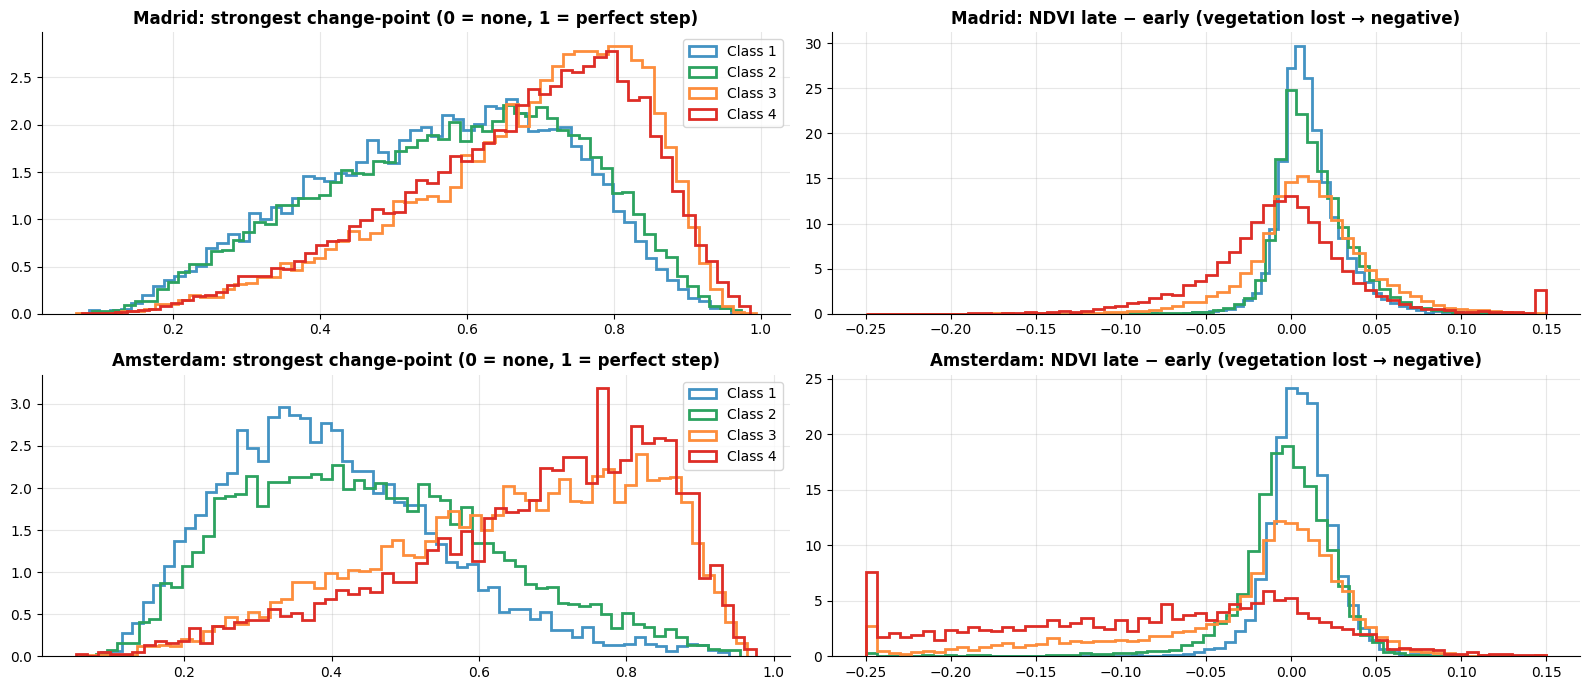

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(16, 7))
for r, c in enumerate(CITIES):
    for k in CLASSES:
        sel = y[c] == k
        axes[r, 0].hist(FEATS[c].loc[sel, 'brk_strength_max'], bins=60, histtype='step', lw=2, density=True, color=CLASS_COLORS[k], label=f'Class {k}')
        axes[r, 1].hist(FEATS[c].loc[sel, 'NDVI_late_minus_early'].clip(-.25, .15), bins=60, histtype='step', lw=2, density=True, color=CLASS_COLORS[k])
    axes[r, 0].set_title(f'{c}: strongest change-point (0 = none, 1 = perfect step)', fontweight='bold'); axes[r, 0].legend()
    axes[r, 1].set_title(f'{c}: NDVI late − early (vegetation lost → negative)', fontweight='bold')
plt.tight_layout(); plt.show()

Classes 3–4 (built while the satellite watched) have **strong breaks** and **lost vegetation**; classes 1–2 do not. The separation is even sharper in **Amsterdam** — exactly the kind of signal that transfers between cities.

### 5.5 Evidence: the feature ablation (from `01-Our_Features.ipynb`, same model throughout)

| Step (cumulative) | Madrid spatial CV | Ams zero-shot | Ams n=25 recalibrated |
|---|---|---|---|
| Starter pipeline | 0.587 | 0.489 | 0.531 |
| Our clean data | 0.599 | 0.413 | 0.548 |
| + per-city scaling | 0.599 | 0.520 | 0.611 |
| + A indices | 0.605 | 0.514 | 0.598 |
| + B robust & trends | 0.618 | 0.540 | 0.602 |
| + C time windows | 0.621 | 0.543 | 0.604 |
| + D change-point | 0.625 | 0.546 | 0.598 |
| + E relative | 0.623 | 0.549 | 0.606 |
| + F quality | 0.623 | 0.538 | 0.603 |
| + G spatial | **0.641** | 0.497 | 0.604 |

**How each addition helped:** every group raised Madrid accuracy (0.587 → 0.641). For transfer, **per-city scaling** gave the largest jump; **change-point (D)** and the **starter-like core (S)** carried unique transfer information (leave-one-group-out drop 0.010–0.019); **spatial features (G)** help Madrid but *hurt* zero-shot (−0.041) because district patterns differ between cities. This drives our two feature sets in Part 6.

### 5.6 Evidence: research upgrades (`02-Experiments.ipynb`, Amsterdam, same 10 draws per n, two machines)

| Configuration | n = 5 | n = 25 | n = 200 | average of 5 n |
|---|---|---|---|---|
| previous FINAL | 0.577 – 0.607 | 0.677 | 0.748 | 0.689 – 0.695 |
| + safe prior correction (no EM when n < 25) | 0.640 – 0.645 | 0.677 | 0.748 | 0.701 – 0.703 |
| + **group H** (two-break & transition features) | **0.651 – 0.652** | **0.682 – 0.683** | **0.753** | **0.708 – 0.709** |
| + TabPFN v2 (GPU only; not adopted) | 0.649 | 0.686 | 0.757 | 0.711 |
| CORAL alignment (rejected) | — | 0.62 – 0.67 | 0.73 | ≤ 0.692 |

Ranges = CPU run and RTX 4060 run. Group H and the safe rule are therefore part of this notebook.

---
# Part 6 — Feature sets, per-city scaling, model-specific preprocessing

### 6.1 Two feature sets
- **RICH set** — the **top 120 features** of all 299 by LightGBM gain importance on Madrid. Used for the **Madrid model** (Stage 1 accuracy). Keeping 120 instead of 299 makes every model ~2.5× faster with no measurable loss. *(Selection uses all Madrid labels once, so Madrid CV on this set is very slightly optimistic; the transfer set below is defined by rule, not by selection.)*
- **TRANSFER set** — **S + D + H + robust index statistics** (median, IQR, slope of 8 indices) = 140 features, **no spatial and no absolute-brightness-only extras**. Used for everything that crosses from Madrid to Amsterdam.

### 6.2 Per-city standardisation
Every feature is converted to *z*-scores **within its own city** (mean 0, std 1), using only that city's unlabelled pixels. A pixel is then described *relative to its own city* — "greener than the typical Amsterdam pixel" — so the darker/greener Amsterdam no longer looks like a different world.

[07:29:45] Feature selection done (10s): RICH=120, TRANSFER=140


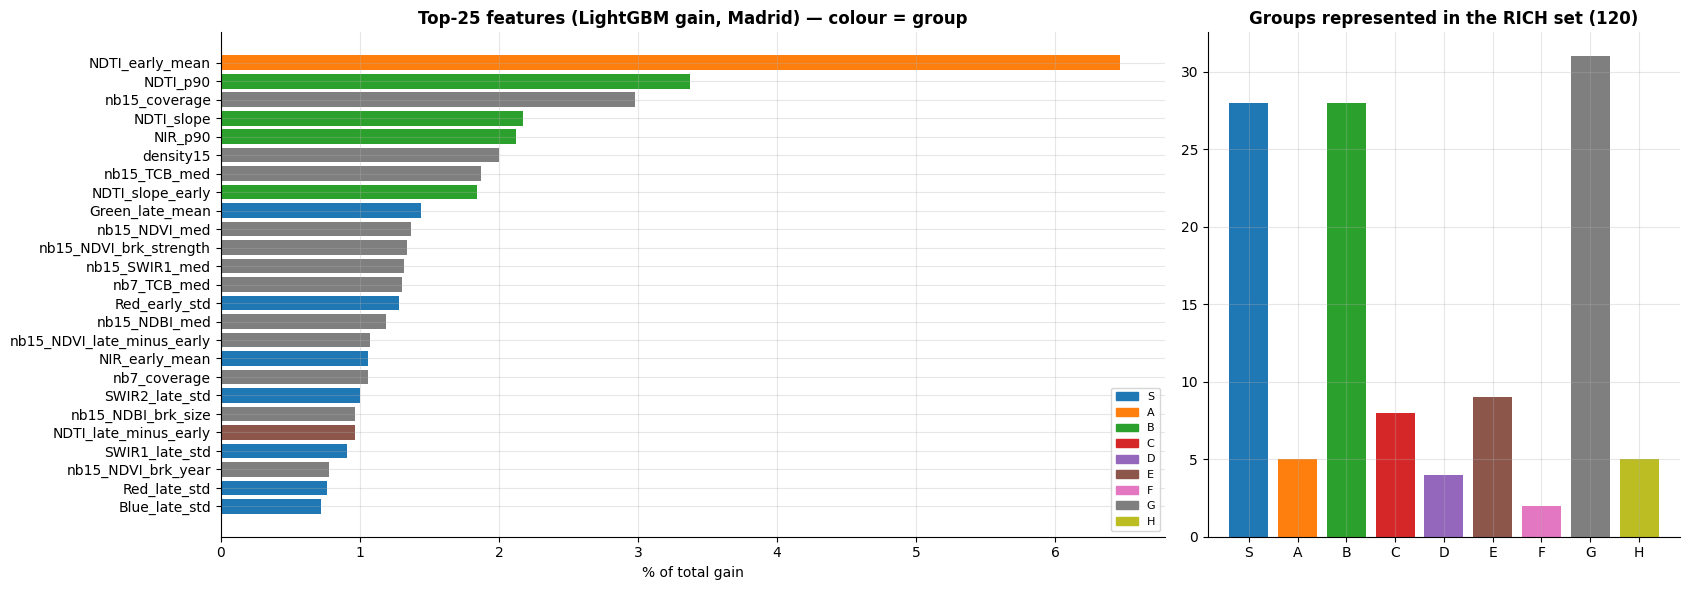

27

In [14]:
def city_scale(X):
    mu = np.nanmean(X, 0); sd = np.nanstd(X, 0); sd[~(sd > 0)] = 1
    return ((X - mu) / sd).astype(np.float32)

ALL_COLS = list(FEATS['Madrid'].columns)
Xall = {c: city_scale(FEATS[c][ALL_COLS].to_numpy(np.float64)) for c in CITIES}

LGB_PARAMS = dict(n_estimators=400, learning_rate=0.05, num_leaves=63, colsample_bytree=0.5, subsample=0.8,
                  subsample_freq=1, min_child_samples=20, n_jobs=N_JOBS, random_state=SEED, verbose=-1)
t = time.time()
sel_model = lgb.LGBMClassifier(**LGB_PARAMS, importance_type='gain').fit(Xall['Madrid'], y['Madrid'], sample_weight=W_MAD)
imp = pd.Series(sel_model.feature_importances_, index=ALL_COLS).sort_values(ascending=False)
RICH = list(imp.index[:120])
TRANSFER = GROUP_COLS['S'] + GROUP_COLS['D'] + GROUP_COLS['H'] + [f'{ch}_{s}' for ch in ['NDVI', 'NDBI', 'MNDWI', 'BSI', 'NBR', 'NDTI', 'TCG', 'TCW']
                                                  for s in ['med', 'iqr', 'slope']]
log(f"Feature selection done ({time.time()-t:.0f}s): RICH={len(RICH)}, TRANSFER={len(TRANSFER)}")

group_of = {f: g for g, cols in GROUP_COLS.items() for f in cols}
fig, ax = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={'width_ratios': [2, 1]})
top = imp.head(25)[::-1]
ax[0].barh(top.index, top.values / imp.sum() * 100, color=[plt.cm.tab10('SABCDEFGH'.index(group_of[f])) for f in top.index])
ax[0].set_xlabel('% of total gain'); ax[0].set_title('Top-25 features (LightGBM gain, Madrid) — colour = group', fontweight='bold')
ax[0].legend(handles=[mpatches.Patch(color=plt.cm.tab10(i), label=g) for i, g in enumerate('SABCDEFGH')], fontsize=8, loc='lower right')
share = pd.Series([group_of[f] for f in RICH]).value_counts().reindex(list('SABCDEFGH')).fillna(0)
ax[1].bar(share.index, share.values, color=[plt.cm.tab10(i) for i in range(9)])
ax[1].set_title('Groups represented in the RICH set (120)', fontweight='bold')
plt.tight_layout(); plt.show()

X = {'RICH': {c: city_scale(FEATS[c][RICH].to_numpy(np.float64)) for c in CITIES},
     'TRANSFER': {c: city_scale(FEATS[c][TRANSFER].to_numpy(np.float64)) for c in CITIES}}
del Xall; gc.collect()

### 6.3 Model-specific preprocessing

| Model | Missing values | Scaling | Class balance | Notes |
|---|---|---|---|---|
| **Random Forest** | **imputed** (0 = city mean after scaling) — sklearn RF cannot take NaN here | not needed (trees), but per-city scaling still aligns cities | sample weights | 300 trees, `min_samples_leaf=2`, `max_features='sqrt'` |
| **Logistic Regression** | imputed | **required** (per-city z-scores) | sample weights | linear; L2 `C=0.5` |
| **MLP neural net** | imputed | **required** | sample weights | 128-64 ReLU, Adam, early stopping |
| **LightGBM** | **native** (learns where NaN should go) | not needed | sample weights | 400 trees, 63 leaves, column/row subsampling |
| **XGBoost** | native | not needed | sample weights | `hist`, depth 6, labels shifted to 0–3 |
| **CatBoost** | native | not needed | sample weights | 400 iterations, depth 6, ordered boosting |

In [15]:
class TorchMLP:
    # GPU MLP: 128-64 ReLU, dropout 0.1, Adam, sample-weighted cross-entropy, early stopping on a 10 % validation split
    def __init__(self, seed=SEED, epochs=60, patience=6, batch=512):
        self.seed, self.epochs, self.patience, self.batch = seed, epochs, patience, batch
    def fit(self, Xm, yv, sample_weight):
        torch.manual_seed(self.seed); rng = np.random.default_rng(self.seed)
        idx = rng.permutation(len(Xm)); nv = max(1, int(.1 * len(Xm))); dev = TORCH_DEV
        Xt = torch.tensor(Xm, dtype=torch.float32, device=dev); yt = torch.tensor(yv - 1, dtype=torch.long, device=dev)
        wt = torch.tensor(sample_weight, dtype=torch.float32, device=dev)
        va = torch.tensor(idx[:nv], device=dev); tr = torch.tensor(idx[nv:], device=dev)
        self.net = nn.Sequential(nn.Linear(Xm.shape[1], 128), nn.ReLU(), nn.Dropout(.1),
                                 nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 4)).to(dev)
        opt = torch.optim.Adam(self.net.parameters(), lr=1e-3, weight_decay=1e-4)
        best, bad, state = np.inf, 0, None
        for ep in range(self.epochs):
            self.net.train(); perm = tr[torch.randperm(len(tr), device=dev)]
            for i in range(0, len(perm), self.batch):
                b = perm[i:i + self.batch]
                loss = (Fnn.cross_entropy(self.net(Xt[b]), yt[b], reduction='none') * wt[b]).sum() / wt[b].sum()
                opt.zero_grad(); loss.backward(); opt.step()
            self.net.eval()
            with torch.no_grad():
                vl = ((Fnn.cross_entropy(self.net(Xt[va]), yt[va], reduction='none') * wt[va]).sum() / wt[va].sum()).item()
            if vl < best - 1e-4:
                best, bad, state = vl, 0, {k: v.clone() for k, v in self.net.state_dict().items()}
            else:
                bad += 1
                if bad >= self.patience: break
        if state: self.net.load_state_dict(state)
        return self
    def predict_proba(self, Xm):
        self.net.eval(); out = []; dev = next(self.net.parameters()).device
        with torch.no_grad():
            for i in range(0, len(Xm), 8192):
                xb = torch.tensor(Xm[i:i + 8192], dtype=torch.float32, device=dev)
                out.append(torch.softmax(self.net(xb), 1).cpu().numpy())
        return np.vstack(out)

if TORCH_DEV:   # self-test; fall back to scikit-learn MLP if the PyTorch install is broken
    try:
        TorchMLP(epochs=1).fit(np.random.rand(100, 5).astype('float32'), np.random.randint(1, 5, 100), np.ones(100)).predict_proba(np.random.rand(10, 5).astype('float32'))
        log('PyTorch GPU MLP self-test passed')
    except Exception as e:
        log(f'PyTorch MLP self-test failed ({e}) -> using scikit-learn MLP on CPU'); TORCH_DEV = None

class Model:
    # one interface for every algorithm: fit(X, y, w) / predict_proba(X) with classes 1–4
    def __init__(self, name):
        self.name = name
        self.impute = name in ('Random Forest', 'Logistic Regression', 'MLP neural net')
        if name == 'Random Forest':
            self.m = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, max_features='sqrt', n_jobs=N_JOBS, random_state=SEED)
        elif name == 'Logistic Regression':
            self.m = LogisticRegression(C=0.5, max_iter=3000)
        elif name == 'MLP neural net' and TORCH_DEV:
            self.m = TorchMLP()
        elif name == 'MLP neural net':
            self.m = MLPClassifier(hidden_layer_sizes=(128, 64), alpha=1e-3, batch_size=256, learning_rate_init=1e-3,
                                   max_iter=60, early_stopping=True, n_iter_no_change=6, random_state=SEED)
        elif name == 'LightGBM':
            self.m = lgb.LGBMClassifier(**LGB_PARAMS)
        elif name == 'XGBoost':
            self.m = xgb.XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.08, subsample=0.8, colsample_bytree=0.5,
                                       tree_method='hist', device=XGB_DEVICE, n_jobs=N_JOBS, random_state=SEED, eval_metric='mlogloss')
        elif name == 'CatBoost':
            self.m = cb.CatBoostClassifier(iterations=400, depth=6, learning_rate=0.08, thread_count=N_JOBS, random_seed=SEED, verbose=0,
                                           task_type=CAT_TASK, **({'devices': '0'} if CAT_TASK == 'GPU' else {}))
    def _prep(self, Xm): return np.nan_to_num(Xm) if self.impute else Xm
    def fit(self, Xm, yv, w):
        self.m.fit(self._prep(Xm), yv - 1 if self.name == 'XGBoost' else yv, sample_weight=w); return self
    def predict_proba(self, Xm): return self.m.predict_proba(self._prep(Xm))

MODEL_NAMES = ['Random Forest', 'Logistic Regression', 'MLP neural net', 'LightGBM', 'XGBoost', 'CatBoost']

[07:29:47] PyTorch GPU MLP self-test passed


---
# Part 7 — Stage 1: Madrid models

### 7.1 Evaluation protocol
- **Spatial-block 5-fold CV** (`StratifiedGroupKFold`, groups = 2 km × 2 km blocks): whole blocks are held out, so the test pixels have no near-identical neighbours in training. Random CV over-estimated macro F1 by ≈ 0.03 in our audit. We report **mean ± std of macro F1** over the 5 folds and the **confusion-matrix proportions** from the out-of-fold (OOF) predictions.
- For each model we also train a **TRANSFER-set version on all Madrid** and score it **zero-shot on Amsterdam** — the first sign of how well it travels.
- Every model starts with **Random Forest** as the baseline, then the other algorithms.

In [16]:
blocks = (pixels['Madrid'].px_key // 67).astype(str) + '_' + (pixels['Madrid'].py_key // 67).astype(str)
CV = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(np.zeros(len(blocks)), y['Madrid'], blocks))
ym = y['Madrid']; ya = y['Amsterdam']

stage1, oof, zs_proba, full_models = {}, {}, {}, {}
for name in MODEL_NAMES:
    try:
        t0 = time.time(); P = np.zeros((len(ym), 4)); scores = []
        for f, (tr, te) in enumerate(CV):
            m = Model(name).fit(X['RICH']['Madrid'][tr], ym[tr], W_MAD[tr])
            P[te] = m.predict_proba(X['RICH']['Madrid'][te]); scores.append(mf1(ym[te], CLASSES[P[te].argmax(1)]))
            log(f"  {name}: fold {f+1}/5 macro F1 {scores[-1]:.3f}")
        full_models[name] = Model(name).fit(X['RICH']['Madrid'], ym, W_MAD)
        mt = Model(name).fit(X['TRANSFER']['Madrid'], ym, W_MAD)
        zs_proba[name] = mt.predict_proba(X['TRANSFER']['Amsterdam'])
        oof[name] = P
        stage1[name] = {'Madrid spatial CV F1': np.mean(scores), '±': np.std(scores),
                        'OOF macro F1': mf1(ym, CLASSES[P.argmax(1)]),
                        'Amsterdam zero-shot F1': mf1(ya, CLASSES[zs_proba[name].argmax(1)]),
                        'minutes': (time.time() - t0) / 60}
        log(f"{name}: CV {np.mean(scores):.3f} ± {np.std(scores):.3f} | zero-shot {stage1[name]['Amsterdam zero-shot F1']:.3f} | {stage1[name]['minutes']:.1f} min")
    except Exception as e:
        log(f"{name}: FAILED — {type(e).__name__}: {e}")

[07:29:55]   Random Forest: fold 1/5 macro F1 0.586


[07:30:04]   Random Forest: fold 2/5 macro F1 0.659


[07:30:12]   Random Forest: fold 3/5 macro F1 0.597


[07:30:21]   Random Forest: fold 4/5 macro F1 0.646


[07:30:29]   Random Forest: fold 5/5 macro F1 0.680


...

[07:33:20]   CatBoost: fold 2/5 macro F1 0.639


[07:33:23]   CatBoost: fold 3/5 macro F1 0.608


[07:33:25]   CatBoost: fold 4/5 macro F1 0.648


[07:33:28]   CatBoost: fold 5/5 macro F1 0.665


[07:33:33] CatBoost: CV 0.631 ± 0.026 | zero-shot 0.593 | 0.3 min


### 7.2 Ensemble
A **soft-voting ensemble** averages the class probabilities of the 3 best models (by Madrid CV). It needs no extra training: we average the stored OOF and zero-shot probabilities.

In [17]:
res1 = pd.DataFrame(stage1).T.sort_values('Madrid spatial CV F1', ascending=False)
TOP3 = list(res1.index[:3])
oof['Ensemble (top-3)'] = np.mean([oof[n] for n in TOP3], axis=0)
zs_proba['Ensemble (top-3)'] = np.mean([zs_proba[n] for n in TOP3], axis=0)
ens_fold = [mf1(ym[te], CLASSES[oof['Ensemble (top-3)'][te].argmax(1)]) for _, te in CV]
res1.loc['Ensemble (top-3)'] = {'Madrid spatial CV F1': np.mean(ens_fold), '±': np.std(ens_fold),
                                'OOF macro F1': mf1(ym, CLASSES[oof['Ensemble (top-3)'].argmax(1)]),
                                'Amsterdam zero-shot F1': mf1(ya, CLASSES[zs_proba['Ensemble (top-3)'].argmax(1)]), 'minutes': 0}
log(f"Top-3 for the ensemble: {TOP3}")
res1 = res1.sort_values('Madrid spatial CV F1', ascending=False)
res1.round(3)

[07:33:33] Top-3 for the ensemble: ['LightGBM', 'XGBoost', 'Random Forest']


,Madrid spatial CV F1,±,OOF macro F1,Amsterdam zero-shot F1,minutes
Ensemble (top-3),0.652,0.026,0.655,0.555,0.000
LightGBM,0.649,0.022,0.651,0.553,0.571
XGBoost,0.646,0.022,0.648,0.564,0.788
Random Forest,0.634,0.036,0.638,0.491,1.082
CatBoost,0.631,0.026,0.634,0.593,0.287
MLP neural net,0.628,0.012,0.630,0.526,0.484
Logistic Regression,0.603,0.021,0.604,0.468,0.546


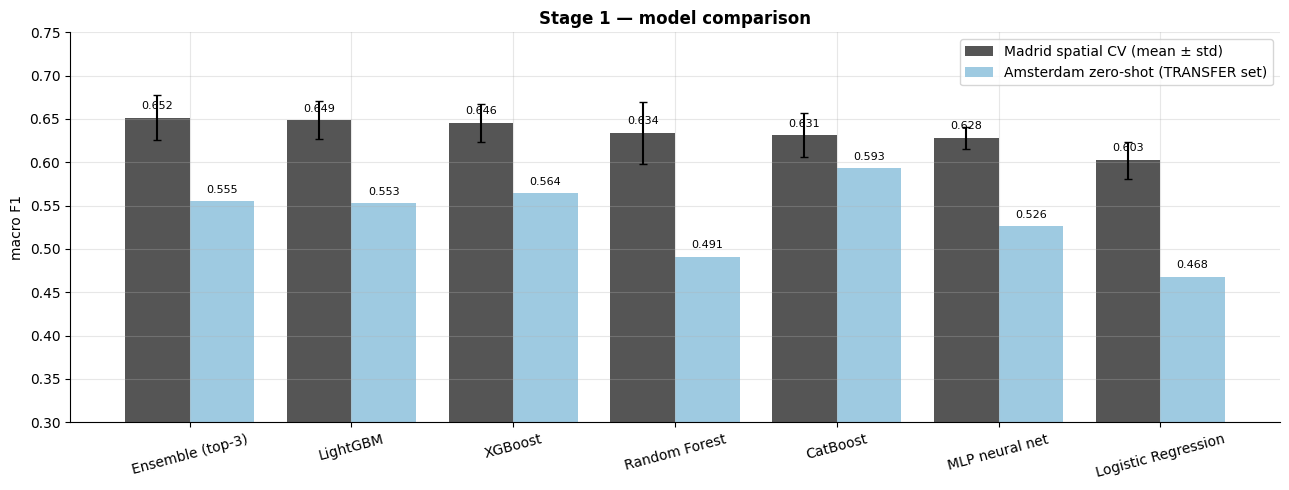

In [18]:
fig, ax = plt.subplots(figsize=(13, 5))
xs = np.arange(len(res1))
ax.bar(xs - .2, res1['Madrid spatial CV F1'], .4, yerr=res1['±'], capsize=3, color='#555555', label='Madrid spatial CV (mean ± std)')
ax.bar(xs + .2, res1['Amsterdam zero-shot F1'], .4, color='#9ecae1', label='Amsterdam zero-shot (TRANSFER set)')
for i, (a, b) in enumerate(zip(res1['Madrid spatial CV F1'], res1['Amsterdam zero-shot F1'])):
    ax.text(i - .2, a + .01, f'{a:.3f}', ha='center', fontsize=8); ax.text(i + .2, b + .01, f'{b:.3f}', ha='center', fontsize=8)
ax.set_xticks(xs); ax.set_xticklabels(res1.index, rotation=15); ax.set_ylim(.3, .75); ax.set_ylabel('macro F1')
ax.set_title('Stage 1 — model comparison', fontweight='bold'); ax.legend(loc='upper right')
plt.tight_layout(); plt.show()

### 7.3 The best Madrid model in detail
Confusion matrix proportions (rows = true class, each row sums to 1 → the diagonal is per-class recall) and the per-class report from out-of-fold predictions.

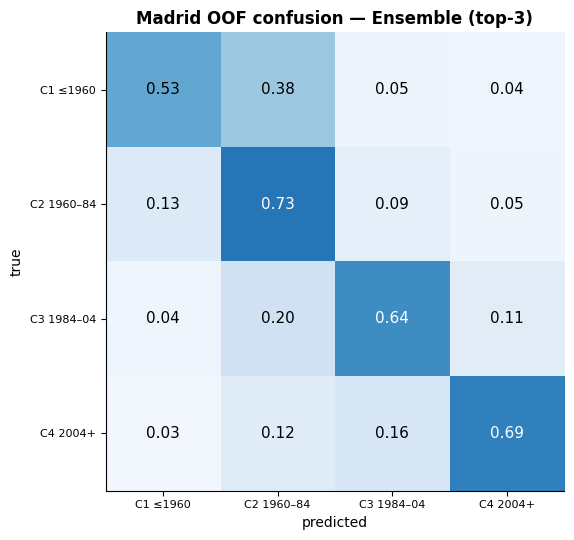

              precision    recall  f1-score   support

           1      0.594     0.528     0.559     13794
           2      0.643     0.731     0.684     27152
           3      0.676     0.642     0.658     18672
           4      0.745     0.690     0.717     16645

    accuracy                          0.664     76263
   macro avg      0.665     0.648     0.655     76263
weighted avg      0.665     0.664     0.662     76263



In [19]:
BEST1 = res1.index[0]
P_best = oof[BEST1]; pred_best = CLASSES[P_best.argmax(1)]
cm = confusion_matrix(ym, pred_best, labels=CLASSES); cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1); ax.grid(False)
for i in range(4):
    for j in range(4): ax.text(j, i, f'{cmn[i, j]:.2f}', ha='center', va='center', color='white' if cmn[i, j] > .55 else 'black', fontsize=11)
labs = ['C1 ≤1960', 'C2 1960–84', 'C3 1984–04', 'C4 2004+']
ax.set_xticks(range(4)); ax.set_xticklabels(labs, fontsize=8); ax.set_yticks(range(4)); ax.set_yticklabels(labs, fontsize=8)
ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(f'Madrid OOF confusion — {BEST1}', fontweight='bold')
plt.tight_layout(); plt.show()
print(classification_report(ym, pred_best, digits=3))

### 7.4 Spatial smoothing of probabilities (tuned on Madrid)

Errors cluster in space, and neighbours usually share a class. After prediction we blend each pixel's probabilities with the **average of its neighbours'**:

$$P_{\text{smooth}} = \alpha\,P_{\text{pixel}} + (1-\alpha)\,\overline{P}_{\text{neighbours}}$$

We choose α and the window size **on Madrid OOF predictions only**, then reuse them unchanged in Amsterdam (no Amsterdam labels involved).

In [20]:
def smooth_proba(P, pix, alpha, size):
    if alpha >= 1: return P
    N = np.column_stack([neigh(pix, P[:, k].astype(np.float64), size) for k in range(4)])
    N = np.where(np.isnan(N), P, N)
    S = alpha * P + (1 - alpha) * N
    return S / S.sum(1, keepdims=True)

grid = []
for size in (3, 5, 7, 11, 15):
    for alpha in (1.0, 0.7, 0.5, 0.3, 0.15):
        Ps = smooth_proba(P_best, pixels['Madrid'], alpha, size)
        grid.append({'size': size, 'alpha': alpha, 'macro F1': mf1(ym, CLASSES[Ps.argmax(1)])})
grid = pd.DataFrame(grid)
best_s = grid.loc[grid['macro F1'].idxmax()]
SMOOTH = dict(alpha=float(best_s.alpha), size=int(best_s['size']))
log(f"Spatial smoothing on Madrid OOF: best {SMOOTH} → macro F1 {best_s['macro F1']:.3f} (unsmoothed {mf1(ym, pred_best):.3f})")
grid.pivot(index='size', columns='alpha', values='macro F1').round(3)

[07:33:36] Spatial smoothing on Madrid OOF: best {'alpha': 0.5, 'size': 5} → macro F1 0.660 (unsmoothed 0.655)


alpha,0.15,0.30,0.50,0.70,1.00
size,,,,,
3,0.652,0.655,0.659,0.659,0.655
5,0.646,0.654,0.660,0.659,0.655
7,0.640,0.650,0.659,0.659,0.655
11,0.627,0.646,0.658,0.659,0.655
15,0.618,0.640,0.656,0.659,0.655


### 7.5 Required Madrid cross-validation (standard random 5-fold) for the best model

The rules ask for cross-validated mean ± std on Madrid. Our main number is the stricter **spatial-block CV** above; for comparability we also report the standard **random stratified 5-fold CV**.

In [21]:
BEST_MEMBERS = TOP3 if BEST1.startswith('Ensemble') else [BEST1]      # an ensemble is retrained member by member
rand_scores = []
for f, (tr, te) in enumerate(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X['RICH']['Madrid'], ym)):
    P = np.mean([Model(n_).fit(X['RICH']['Madrid'][tr], ym[tr], W_MAD[tr]).predict_proba(X['RICH']['Madrid'][te])
                 for n_ in BEST_MEMBERS], axis=0)
    rand_scores.append(mf1(ym[te], CLASSES[P.argmax(1)]))
    log(f"  random CV fold {f+1}/5: {rand_scores[-1]:.3f}")
log(f"{BEST1}: random 5-fold CV {np.mean(rand_scores):.3f} ± {np.std(rand_scores):.3f} | spatial {res1.loc[BEST1, 'Madrid spatial CV F1']:.3f} ± {res1.loc[BEST1, '±']:.3f}")
MADRID_RESULT = {'model': BEST1, 'spatial CV mean': res1.loc[BEST1, 'Madrid spatial CV F1'], 'spatial CV std': res1.loc[BEST1, '±'],
                 'random CV mean': np.mean(rand_scores), 'random CV std': np.std(rand_scores),
                 'spatial CV + smoothing (OOF)': best_s['macro F1']}
pd.Series(MADRID_RESULT).to_frame('Madrid')

[07:33:56]   random CV fold 1/5: 0.735


[07:34:26]   random CV fold 2/5: 0.737


[07:35:17]   random CV fold 3/5: 0.741


[07:36:05]   random CV fold 4/5: 0.734


[07:36:26]   random CV fold 5/5: 0.735


[07:36:26] Ensemble (top-3): random 5-fold CV 0.736 ± 0.003 | spatial 0.652 ± 0.026


,Madrid
model,Ensemble (top-3)
spatial CV mean,0.651611
spatial CV std,0.025536
random CV mean,0.736363
random CV std,0.002561
spatial CV + smoothing (OOF),0.659826


---
# Part 8 — Stage 2: transfer to Amsterdam

### 8.1 Choosing the transfer base model
For transfer we use the model with the **best Amsterdam zero-shot F1 on the TRANSFER set** (it travels best). For the **fine-tuning** method we always use **LightGBM**, because it must be retrained 50 times (5 sizes × 10 draws) and is the fastest strong model.

In [22]:
zs_table = res1[['Amsterdam zero-shot F1']].sort_values('Amsterdam zero-shot F1', ascending=False)
BASE = zs_table.index[0]
PZ = zs_proba[BASE]
log(f"Transfer base model (best zero-shot): {BASE} → {zs_table.iloc[0, 0]:.3f}")
zs_table.round(3).T

[07:36:26] Transfer base model (best zero-shot): CatBoost → 0.593


,CatBoost,XGBoost,Ensemble (top-3),LightGBM,MLP neural net,Random Forest,Logistic Regression
Amsterdam zero-shot F1,0.593,0.564,0.555,0.553,0.526,0.491,0.468


### 8.2 Zero-shot step by step (no Amsterdam labels at all)

1. **Madrid scaling** (starter style) → 2. **per-city scaling** → 3. **+ EM class-prior correction** → 4. **+ spatial smoothing** → 5. **per-city scaling + smoothing without EM** (the variant we use: without labels, EM is unreliable — see below).

**EM prior correction (Saerens et al., 2002).** The model was trained with balanced weights, so it implicitly assumes 25 % per class. Amsterdam's true mix is different and unknown. EM alternates: (a) estimate the class mix as the average predicted probability; (b) re-weight every pixel's probabilities by *new mix ÷ training mix* — until stable. It uses only unlabelled pixels.

In [23]:
def em_prior(P, prior_train=np.full(4, .25), iters=200, tol=1e-6):
    pi = prior_train.copy()
    for _ in range(iters):
        Q = P * (pi / prior_train); Q /= Q.sum(1, keepdims=True)
        new = Q.mean(0)
        if np.abs(new - pi).max() < tol: break
        pi = new
    return Q, pi

sc = StandardScaler().fit(FEATS['Madrid'][TRANSFER].to_numpy(np.float64))
m_madscale = lgb.LGBMClassifier(**LGB_PARAMS).fit(sc.transform(FEATS['Madrid'][TRANSFER].to_numpy(np.float64)), ym, sample_weight=W_MAD)
P_madscale = m_madscale.predict_proba(sc.transform(FEATS['Amsterdam'][TRANSFER].to_numpy(np.float64)))
PZ_em, pi_est = em_prior(PZ)
PZ_em_s = smooth_proba(PZ_em, pixels['Amsterdam'], **SMOOTH)
PZ_s = smooth_proba(PZ, pixels['Amsterdam'], **SMOOTH)
zero_chain = pd.DataFrame({'zero-shot variant': ['1 LightGBM, Madrid scaling (starter style)', f'2 {BASE}, per-city scaling',
                                                 '3 + EM class-prior correction', '4 + EM + spatial smoothing',
                                                 '5 per-city scaling + spatial smoothing (no EM)  ← used'],
                           'macro F1': [mf1(ya, CLASSES[P.argmax(1)]) for P in (P_madscale, PZ, PZ_em, PZ_em_s, PZ_s)]})
true_mix = np.bincount(ya, minlength=5)[1:] / len(ya)
log("EM-estimated Amsterdam class mix: " + ', '.join(f'C{k}={p:.2f}' for k, p in zip(CLASSES, pi_est)) +
    "  | true: " + ', '.join(f'C{k}={p:.2f}' for k, p in zip(CLASSES, true_mix)))
zero_chain.round(3)

[07:36:33] EM-estimated Amsterdam class mix: C1=0.00, C2=0.56, C3=0.26, C4=0.17  | true: C1=0.29, C2=0.34, C3=0.26, C4=0.11


,zero-shot variant,macro F1
0,"1 LightGBM, Madrid scaling (starter style)",0.519
1,"2 CatBoost, per-city scaling",0.593
2,3 + EM class-prior correction,0.459
3,4 + EM + spatial smoothing,0.468
4,5 per-city scaling + spatial smoothing (no EM)...,0.624


### 8.3 Few-shot transfer methods

For each draw: **support** = n random labelled Amsterdam pixels per class; **query** = all other Amsterdam pixels (scored). Nothing is tuned on query labels — all settings come from Madrid or are fixed by rule.

| Method | How it works | Uses Madrid? | Uses unlabelled Amsterdam? |
|---|---|---|---|
| **Prototype** (starter baseline) | class means of the support set; nearest mean wins | ❌ | ❌ |
| **Recalibration** | logistic regression re-maps the base model's 4 log-probabilities, fitted on the support set | ✅ | ❌ |
| **Fine-tune** | retrain LightGBM on **Madrid + support**, each support pixel weighted so the support carries 25 % of the total weight | ✅ | ❌ |
| **Self-training** | from the average of recalibration + fine-tune, take the 500 most confident query pixels per class as **pseudo-labels**; train a small LightGBM on support (weight 3) + pseudo-labels (weight = confidence) | ✅ | ✅ |
| **Ensemble** | average of recalibration, fine-tune, self-training | ✅ | ✅ |
| **FINAL = Ensemble + safe EM prior + smoothing** | the ensemble, then the class-mix correction **only when n ≥ 25** (with fewer labels the probabilities are too noisy to estimate a class mix — research upgrade 1), then the Madrid-tuned spatial smoothing | ✅ | ✅ |
| *Variant: + label propagation* | the FINAL probabilities, with the support labels fixed and spread to neighbours over 10 smoothing rounds | ✅ | ✅ |

*Label propagation only helps when the scored pixels lie near labelled ones; we report it separately and check robustness on far-away pixels (8.6).*

In [24]:
XA_T, XM_T = X['TRANSFER']['Amsterdam'], X['TRANSFER']['Madrid']
XA_T0 = np.nan_to_num(XA_T)
PIX_A = pixels['Amsterdam']
LOGPZ = np.log(PZ + 1e-6)
FT_PARAMS = dict(LGB_PARAMS, n_estimators=300)
ST_PARAMS = dict(n_estimators=200, learning_rate=0.05, num_leaves=15, min_child_samples=10, colsample_bytree=0.7,
                 n_jobs=N_JOBS, random_state=SEED, verbose=-1)

def sample_support(yv, n, seed):
    rng = np.random.default_rng(seed)
    s = np.concatenate([rng.choice(np.where(yv == k)[0], n, replace=False) for k in CLASSES])
    return s, np.setdiff1d(np.arange(len(yv)), s)

def adapt_to_city(s, y_s, X_target=XA_T, logp_target=LOGPZ, pix_target=PIX_A, seed=SEED):
    # Stage-2 adaptation. s = indices of labelled target pixels, y_s = their classes.
    out = {}
    # prototype (starter baseline)
    Xt0 = np.nan_to_num(X_target); P_ = np.stack([Xt0[s][y_s == k].mean(0) for k in CLASSES])
    d = (Xt0 ** 2).sum(1)[:, None] - 2 * Xt0 @ P_.T + (P_ ** 2).sum(1)[None]
    out['Prototype'] = np.eye(4)[d.argmin(1)]
    # recalibration
    out['Recalibration'] = LogisticRegression(C=1.0, max_iter=3000).fit(logp_target[s], y_s).predict_proba(logp_target)
    # fine-tune: Madrid + weighted support
    w_s = np.full(len(s), 0.25 * W_MAD.sum() / len(s))
    ft = lgb.LGBMClassifier(**dict(FT_PARAMS, random_state=seed)).fit(
        np.vstack([XM_T, X_target[s]]), np.r_[ym, y_s], sample_weight=np.r_[W_MAD, w_s])
    out['Fine-tune'] = ft.predict_proba(X_target)
    # self-training with pseudo-labels
    base = (out['Recalibration'] + out['Fine-tune']) / 2
    pool = np.setdiff1d(np.arange(len(X_target)), s); pred = base[pool].argmax(1)
    ps, py, pw = [], [], []
    for k in range(4):
        cand = pool[pred == k]
        if len(cand):
            top = cand[np.argsort(-base[cand, k])[:500]]; ps.append(top); py.append(np.full(len(top), k + 1)); pw.append(base[top, k])
    idx = np.r_[s, np.concatenate(ps)]
    st = lgb.LGBMClassifier(**dict(ST_PARAMS, random_state=seed)).fit(
        X_target[idx], np.r_[y_s, np.concatenate(py)], sample_weight=np.r_[np.full(len(s), 3.0), np.concatenate(pw)])
    out['Self-training'] = st.predict_proba(X_target)
    # ensemble → prior correction → smoothing
    ens = (out['Recalibration'] + out['Fine-tune'] + out['Self-training']) / 3
    out['Ensemble'] = ens
    n_per_class = len(s) // 4
    fin = em_prior(ens)[0] if n_per_class >= 25 else ens          # safe prior correction
    fin = smooth_proba(fin, pix_target, **SMOOTH)
    out['FINAL (ensemble + prior + smoothing)'] = fin
    # variant: label propagation from the support pixels
    Y_s = np.eye(4)[y_s - 1]; P = fin.copy(); P[s] = Y_s
    for _ in range(10):
        P = smooth_proba(P, pix_target, 0.5, max(SMOOTH['size'], 5))
        P = 0.5 * fin + 0.5 * P; P[s] = Y_s
    out['FINAL + label propagation'] = P
    return out

METHODS = ['Prototype', 'Recalibration', 'Fine-tune', 'Self-training', 'Ensemble',
           'FINAL (ensemble + prior + smoothing)', 'FINAL + label propagation']
log("Stage-2 adaptation function ready")

[07:36:33] Stage-2 adaptation function ready


### 8.4 Running the full protocol: n = 5, 25, 50, 100, 200 × 10 draws

This is the **Amsterdam cross-validation required by the challenge**: for each sample size, 10 independent random support/query splits (seeds 0–9) → mean ± std of macro F1 per method. We also keep per-class F1 for the FINAL method and, at n = 25, the score on **far-away query pixels** (≥ 1 km from every support pixel).

In [25]:
xy_A = PIX_A[PID].to_numpy(np.float64)
rows, perclass, far_scores = [], [], []
t0 = time.time()
for n in N_SHOTS:
    for d in range(N_DRAWS):
        s, q = sample_support(ya, n, d)
        out = adapt_to_city(s, ya[s], seed=d)
        for mth in METHODS:
            rows.append({'n': n, 'draw': d, 'method': mth, 'macro F1': mf1(ya[q], CLASSES[out[mth][q].argmax(1)])})
        fin_pred = CLASSES[out['FINAL (ensemble + prior + smoothing)'][q].argmax(1)]
        perclass.append({'n': n, 'draw': d, **{f'C{k}': v for k, v in zip(CLASSES, f1_score(ya[q], fin_pred, average=None, labels=CLASSES))}})
        if n == 25:
            dist, _ = cKDTree(xy_A[s]).query(xy_A[q]); far = dist >= 33
            for mth in METHODS:
                far_scores.append({'draw': d, 'method': mth, 'macro F1 (≥1 km)': mf1(ya[q][far], CLASSES[out[mth][q][far].argmax(1)]),
                                   'far pixels': int(far.sum())})
        last = {m_: rows[-len(METHODS) + i]['macro F1'] for i, m_ in enumerate(METHODS)}
        log(f"n={n:3d} draw {d}: FINAL {last['FINAL (ensemble + prior + smoothing)']:.3f} | proto {last['Prototype']:.3f} | "
            f"recal {last['Recalibration']:.3f} | ft {last['Fine-tune']:.3f}  ({(time.time()-t0)/60:.1f} min)")
fs = pd.DataFrame(rows)
summary = fs.groupby(['method', 'n'])['macro F1'].agg(['mean', 'std']).unstack('n')
summary = summary.reindex(METHODS)
summary.round(3)

[07:36:40] n=  5 draw 0: FINAL 0.679 | proto 0.584 | recal 0.609 | ft 0.627  (0.1 min)


[07:36:46] n=  5 draw 1: FINAL 0.660 | proto 0.464 | recal 0.510 | ft 0.602  (0.2 min)


[07:36:51] n=  5 draw 2: FINAL 0.621 | proto 0.499 | recal 0.506 | ft 0.605  (0.3 min)


[07:37:04] n=  5 draw 3: FINAL 0.668 | proto 0.551 | recal 0.581 | ft 0.615  (0.5 min)


[07:37:23] n=  5 draw 4: FINAL 0.631 | proto 0.490 | recal 0.542 | ft 0.602  (0.8 min)


...

[07:44:18] n=200 draw 6: FINAL 0.757 | proto 0.629 | recal 0.646 | ft 0.714  (7.7 min)


[07:44:23] n=200 draw 7: FINAL 0.754 | proto 0.628 | recal 0.644 | ft 0.708  (7.8 min)


[07:44:29] n=200 draw 8: FINAL 0.755 | proto 0.613 | recal 0.645 | ft 0.709  (7.9 min)


[07:44:36] n=200 draw 9: FINAL 0.754 | proto 0.639 | recal 0.647 | ft 0.705  (8.0 min)


mean                                std                            
n                                       5      25     50     100    200    5      25     50     100    200
method                                                                                                    
Prototype                             0.518  0.607  0.620  0.630  0.631  0.040  0.016  0.009  0.010  0.008
Recalibration                         0.564  0.627  0.639  0.641  0.643  0.039  0.016  0.008  0.004  0.003
Fine-tune                             0.606  0.644  0.666  0.692  0.711  0.010  0.006  0.007  0.005  0.003
Self-training                         0.626  0.662  0.687  0.704  0.722  0.020  0.012  0.007  0.006  0.003
Ensemble                              0.635  0.668  0.691  0.707  0.723  0.022  0.012  0.005  0.004  0.002
FINAL (ensemble + prior + smoothing)  0.654  0.687  0.723  0.740  0.757  0.022  0.020  0.004  0.004  0.002
FINAL + label propagation             0.659  0.690  0.727  0.745  0.761  0.021  0.023  0.005  0.004  0.002

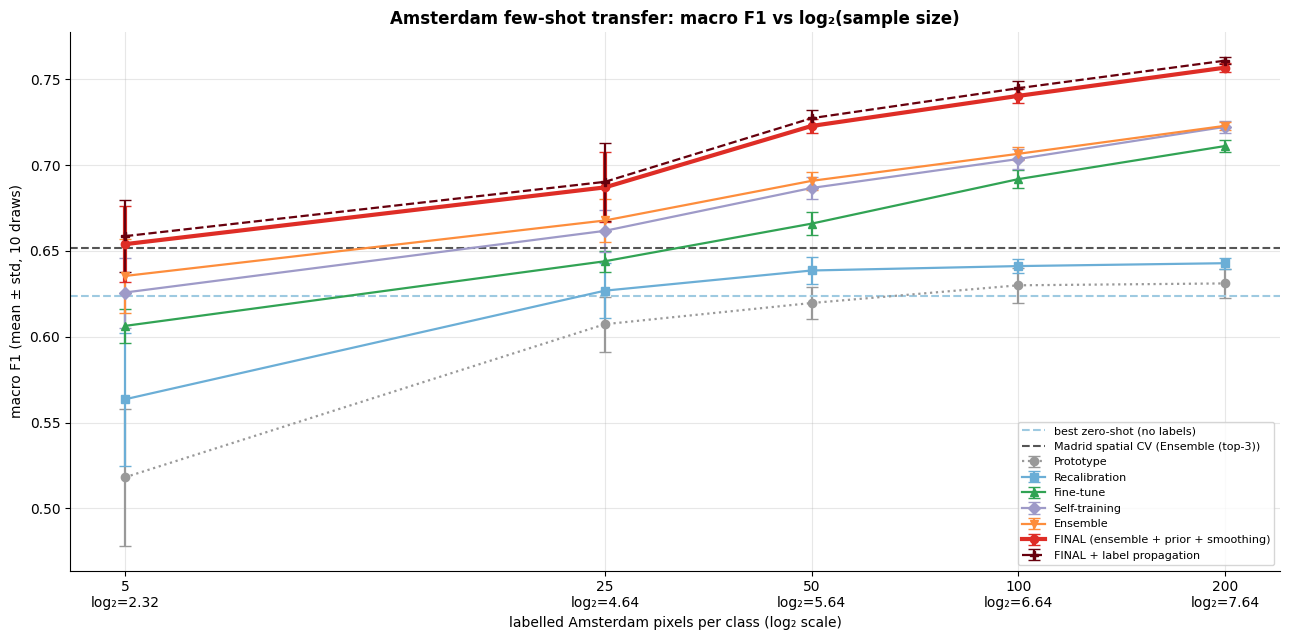

In [26]:
fig, ax = plt.subplots(figsize=(13, 6.5))
styles = {'Prototype': ('#999999', 'o', ':'), 'Recalibration': ('#6baed6', 's', '-'), 'Fine-tune': ('#31a354', '^', '-'),
          'Self-training': ('#9e9ac8', 'D', '-'), 'Ensemble': ('#fd8d3c', 'v', '-'),
          'FINAL (ensemble + prior + smoothing)': ('#de2d26', 'o', '-'), 'FINAL + label propagation': ('#67000d', 'P', '--')}
lx = np.log2(N_SHOTS)
for mth in METHODS:
    col, mk, ls = styles[mth]
    mu, sd = summary.loc[mth, 'mean'].values, summary.loc[mth, 'std'].values
    ax.errorbar(lx, mu, yerr=sd, marker=mk, ls=ls, color=col, capsize=4, lw=3 if mth.startswith('FINAL (') else 1.6, label=mth)
ax.axhline(zero_chain['macro F1'].max(), color='#9ecae1', ls='--', label='best zero-shot (no labels)')
ax.axhline(MADRID_RESULT['spatial CV mean'], color='#555555', ls='--', label=f'Madrid spatial CV ({BEST1})')
ax.set_xticks(lx); ax.set_xticklabels([f'{n}\nlog₂={l:.2f}' for n, l in zip(N_SHOTS, lx)])
ax.set_xlabel('labelled Amsterdam pixels per class (log₂ scale)'); ax.set_ylabel('macro F1 (mean ± std, 10 draws)')
ax.set_title('Amsterdam few-shot transfer: macro F1 vs log₂(sample size)', fontweight='bold'); ax.legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.savefig(OUT_DIR / 'f1_vs_log2_n.png', dpi=150, bbox_inches='tight'); plt.show()

### 8.5 Per-class behaviour of the FINAL method

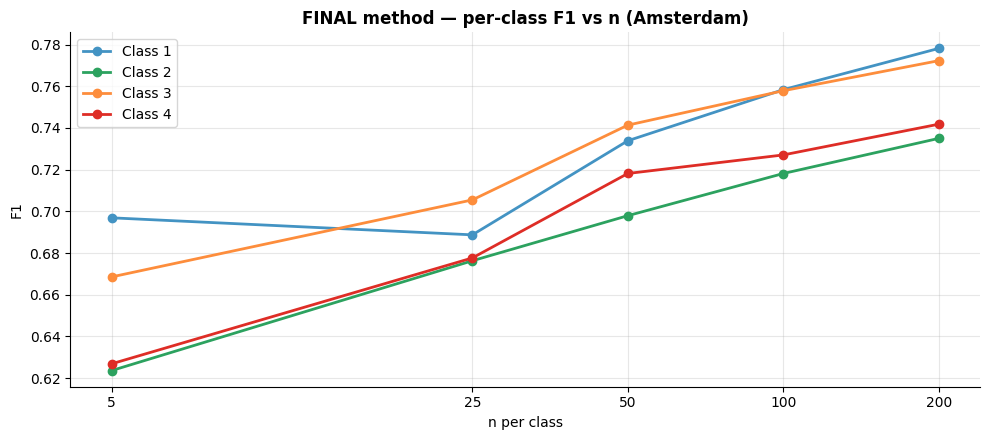

,C1,C2,C3,C4
n,,,,
5,0.697,0.624,0.669,0.627
25,0.689,0.676,0.705,0.678
50,0.734,0.698,0.741,0.718
100,0.758,0.718,0.758,0.727
200,0.778,0.735,0.772,0.742


In [27]:
pc = pd.DataFrame(perclass).groupby('n')[[f'C{k}' for k in CLASSES]].mean()
fig, ax = plt.subplots(figsize=(10, 4.5))
for k in CLASSES: ax.plot(np.log2(pc.index), pc[f'C{k}'], marker='o', color=CLASS_COLORS[k], lw=2, label=f'Class {k}')
ax.set_xticks(np.log2(N_SHOTS)); ax.set_xticklabels(N_SHOTS); ax.set_xlabel('n per class'); ax.set_ylabel('F1')
ax.set_title('FINAL method — per-class F1 vs n (Amsterdam)', fontweight='bold'); ax.legend()
plt.tight_layout(); plt.show()
pc.round(3)

### 8.6 Robustness: pixels far from any labelled pixel (n = 25)
If a method only works by copying labels from nearby support pixels, its score collapses on pixels ≥ 1 km away. This tells us which methods would still work if the organisers' hidden test pixels are not next to our labelled ones.

In [28]:
far_df = pd.DataFrame(far_scores).groupby('method')[['macro F1 (≥1 km)', 'far pixels']].mean().reindex(METHODS)
far_df['macro F1 (all query, n=25)'] = summary.loc[METHODS, ('mean', 25)].values
far_df.round(3)

,macro F1 (≥1 km),far pixels,"macro F1 (all query, n=25)"
method,,,
Prototype,0.499,4079.7,0.607
Recalibration,0.531,4079.7,0.627
Fine-tune,0.534,4079.7,0.644
Self-training,0.548,4079.7,0.662
Ensemble,0.553,4079.7,0.668
FINAL (ensemble + prior + smoothing),0.562,4079.7,0.687
FINAL + label propagation,0.561,4079.7,0.690


### 8.7 Map: Amsterdam, n = 25 (draw 0)
True classes vs FINAL predictions vs errors (standard class colours: C1 blue, C2 green, C3 orange, C4 red).

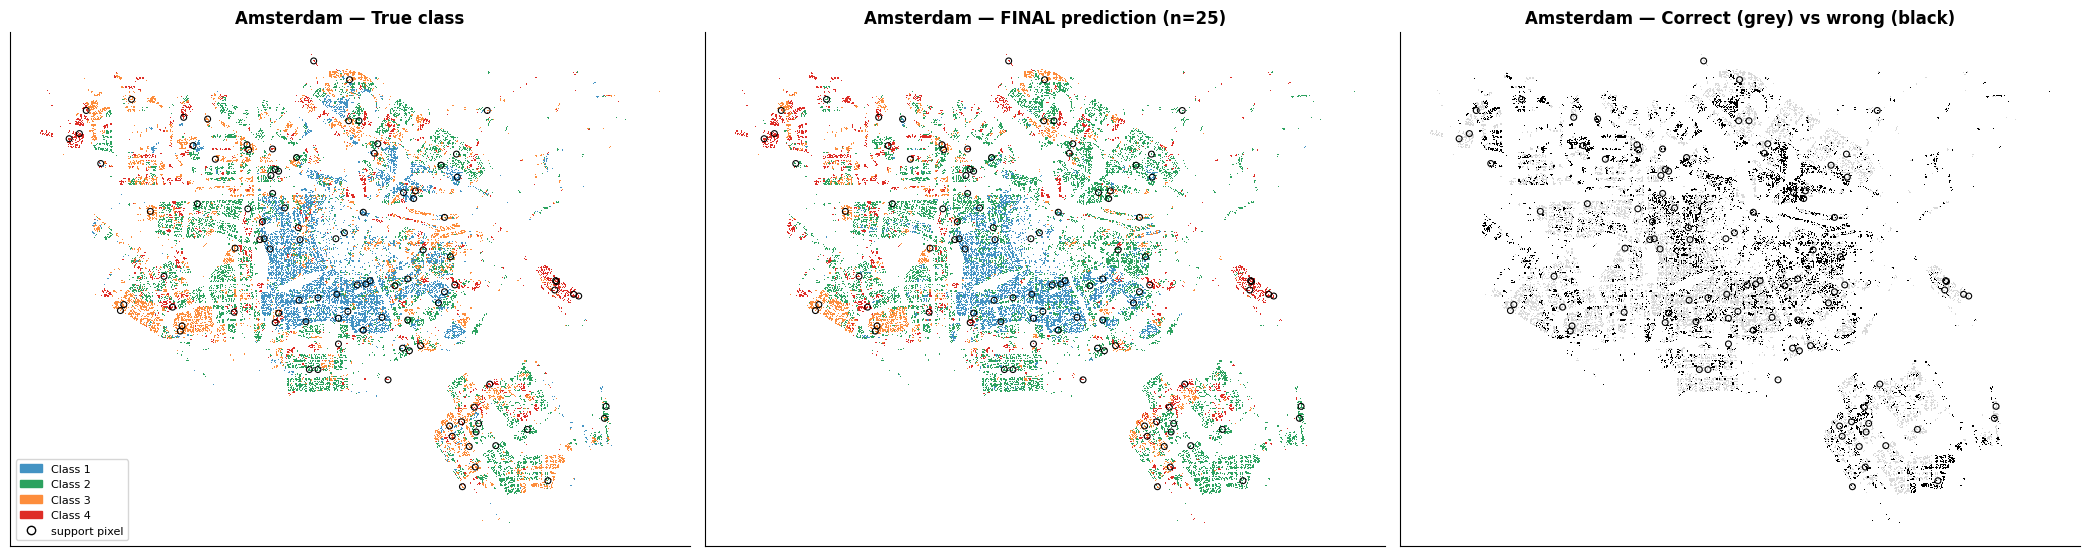

[07:44:43] Map draw: FINAL macro F1 on query = 0.642


In [29]:
s, q = sample_support(ya, 25, 0); out = adapt_to_city(s, ya[s], seed=0)
pred = CLASSES[out['FINAL (ensemble + prior + smoothing)'].argmax(1)]
cmap = np.array([CLASS_COLORS[k] for k in CLASSES])
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for ax, (title, colours) in zip(axes, [('True class', cmap[ya - 1]), ('FINAL prediction (n=25)', cmap[pred - 1]),
                                       ('Correct (grey) vs wrong (black)', np.where(pred == ya, '#d9d9d9', '#000000'))]):
    ax.scatter(PIX_A.px_key, PIX_A.py_key, c=colours, s=.6, marker='s', linewidths=0)
    ax.scatter(PIX_A.px_key.iloc[s], PIX_A.py_key.iloc[s], s=18, facecolors='none', edgecolors='k', lw=.8)
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f'Amsterdam — {title}', fontweight='bold')
axes[0].legend(handles=[mpatches.Patch(color=CLASS_COLORS[k], label=f'Class {k}') for k in CLASSES] +
               [plt.Line2D([], [], marker='o', ls='', mfc='none', mec='k', label='support pixel')], loc='lower left', fontsize=8)
plt.tight_layout(); plt.show()
log(f"Map draw: FINAL macro F1 on query = {mf1(ya[q], pred[q]):.3f}")

---
# Part 9 — Required results

**Deliverable table** (macro F1, mean ± std). Madrid: 5-fold CV of the Stage-1 model. Amsterdam: FINAL method, 10 random support/query draws per sample size.

In [30]:
FINAL = 'FINAL (ensemble + prior + smoothing)'
req = pd.DataFrame({
    'setting': ['Madrid — spatial-block 5-fold CV', 'Madrid — random 5-fold CV'] + [f'Amsterdam — n = {n} per class' for n in N_SHOTS],
    'macro F1 mean': [MADRID_RESULT['spatial CV mean'], MADRID_RESULT['random CV mean']] + list(summary.loc[FINAL, 'mean'].values),
    'macro F1 std':  [MADRID_RESULT['spatial CV std'], MADRID_RESULT['random CV std']] + list(summary.loc[FINAL, 'std'].values)})
req['log2(n)'] = [np.nan, np.nan] + list(np.log2(N_SHOTS))
req.to_csv(OUT_DIR / 'required_results.csv', index=False)
summary.to_csv(OUT_DIR / 'few_shot_all_methods.csv')
res1.to_csv(OUT_DIR / 'stage1_model_comparison.csv')
log("Required results:\n" + req.round(3).to_string(index=False))
req.round(3)

[07:44:43] Required results:
                         setting  macro F1 mean  macro F1 std  log2(n)
Madrid — spatial-block 5-fold CV          0.652         0.026      NaN
       Madrid — random 5-fold CV          0.736         0.003      NaN
     Amsterdam — n = 5 per class          0.654         0.022    2.322
    Amsterdam — n = 25 per class          0.687         0.020    4.644
    Amsterdam — n = 50 per class          0.723         0.004    5.644
   Amsterdam — n = 100 per class          0.740         0.004    6.644
   Amsterdam — n = 200 per class          0.757         0.002    7.644


,setting,macro F1 mean,macro F1 std,log2(n)
0,Madrid — spatial-block 5-fold CV,0.652,0.026,NaN
1,Madrid — random 5-fold CV,0.736,0.003,NaN
2,Amsterdam — n = 5 per class,0.654,0.022,2.322
3,Amsterdam — n = 25 per class,0.687,0.020,4.644
4,Amsterdam — n = 50 per class,0.723,0.004,5.644
5,Amsterdam — n = 100 per class,0.740,0.004,6.644
6,Amsterdam — n = 200 per class,0.757,0.002,7.644


In [31]:
prize = pd.DataFrame({
    'Best average F1 (mean of 5 n)': summary.xs('mean', axis=1, level=0).mean(1),
    'Best peak F1 (max over n)':     summary.xs('mean', axis=1, level=0).max(1),
    'Best low-data F1 (n = 25)':     summary[('mean', 25)]}).reindex(METHODS)
prize.round(3)

,Best average F1 (mean of 5 n),Best peak F1 (max over n),Best low-data F1 (n = 25)
method,,,
Prototype,0.601,0.631,0.607
Recalibration,0.623,0.643,0.627
Fine-tune,0.664,0.711,0.644
Self-training,0.680,0.722,0.662
Ensemble,0.685,0.723,0.668
FINAL (ensemble + prior + smoothing),0.712,0.757,0.687
FINAL + label propagation,0.716,0.761,0.690


---
# Part 10 — What worked and what did not

### ✅ What worked

| Idea | Evidence |
|---|---|
| **Cleaning + warm-season median composite** | year-to-year noise −46 % (Madrid) / −40 % (Amsterdam); Madrid F1 0.587 → 0.599 with identical features |
| **Per-city standardisation** | zero-shot 0.519 (starter-style scaling) → 0.593 |
| **Spatial smoothing for zero-shot** | 0.593 → **0.624** with no labels at all |
| **Change-point features** (one break, D; two breaks & transition, H) | break strength separates built-before vs built-during-the-record classes in both cities; H added +0.004 to +0.011 at every n |
| **Gradient boosting** | LightGBM 0.649 / XGBoost 0.646 > Random Forest 0.634 > CatBoost 0.631 > MLP 0.628 > Logistic Regression 0.603 (spatial CV); top-3 ensemble 0.652 |
| **Transfer methods that reuse Madrid + unlabelled Amsterdam** | n = 25: prototype 0.607 → recalibration 0.627 → fine-tune 0.644 → self-training 0.662 → ensemble 0.668 → FINAL 0.687 |
| **Safe prior correction** (EM only when n ≥ 25) | n = 5: 0.597 → **0.654**, spread ±0.061 → ±0.022 |
| **Spatial-block CV** | exposes the optimism of random CV (0.736 vs 0.652) — every model choice used the honest number |

### ❌ What did not work (and what we learned)

| Idea | What happened | Lesson |
|---|---|---|
| **EM prior correction without labels** | zero-shot 0.593 → 0.459; estimated 0 % class 1 (true 29 %) | under domain shift the probabilities are miscalibrated and EM amplifies the bias |
| **BCTS calibration** (Alexandari et al. 2020) | did not rescue zero-shot EM; calibration alone lowered zero-shot | the Madrid → Amsterdam shift is not a simple calibration problem |
| **CORAL feature alignment** | −0.05 at n = 25 | forcing Madrid's feature correlations onto Amsterdam distorts real city differences |
| **Iterative, spatially consistent self-training** | ties one-round self-training | not worth 3× the compute |
| **TabPFN v2** (*Nature* 2025) | +0.003 average — inside the error bars | not adopted: GPU-only, older library versions, model download — a reproducibility risk for no reliable gain |
| **Spatial features for transfer** | zero-shot −0.041 when used as model input | district patterns differ between cities → used for Madrid and as post-prediction smoothing only |
| **Prototype & pure recalibration** | plateau at ≈ 0.63–0.64 even with 200 labels | they cannot move the decision boundary — fine-tuning and self-training can |
| **Intel Iris Xe integrated GPU** | ≈ 9× slower than the CPU | a dedicated NVIDIA GPU cut the full run from ≈ 55 to 18 minutes |
| **Far-away pixels** (≥ 1 km from any label, n = 25) | every method drops (FINAL 0.562, prototype 0.499) but the ranking is unchanged | our gain is not neighbour-copying; outskirts are simply harder |

---
# Part 11 — Deliverables

1. **Trained Stage-1 models** → `submission/stage1_madrid_rich_<model>.joblib` (best Madrid model) and `submission/stage1_transfer_base.joblib` (transfer base) + the feature lists.
2. **Training / adaptation code** → this notebook; `adapt_to_city(support_indices, support_labels)` is parameterised by the sample size *n* via `sample_support(y, n, seed)` and runs with fixed seeds.
3. **Results for the slides** → `required_results.csv`, `few_shot_all_methods.csv`, `stage1_model_comparison.csv`, `f1_vs_log2_n.png`.
4. **Abstract (≤ 150 words)** and **written justification (≤ 300 words)** → drafts below.

In [32]:
joblib.dump({'models': [full_models[n_] for n_ in BEST_MEMBERS], 'names': BEST_MEMBERS, 'combine': 'average of predict_proba',
             'features': RICH, 'scaling': 'per-city z-score'},
            OUT_DIR / f"stage1_madrid_rich_{BEST1.replace(' ', '_').replace('(', '').replace(')', '')}.joblib")
base_names = TOP3 if BASE.startswith('Ensemble') else [BASE]
base_full = [Model(n_).fit(X['TRANSFER']['Madrid'], ym, W_MAD) for n_ in base_names]   # averaged if more than one
joblib.dump({'models': base_full, 'names': base_names, 'features': TRANSFER, 'scaling': 'per-city z-score', 'smoothing': SMOOTH}, OUT_DIR / 'stage1_transfer_base.joblib')
json.dump({'RICH': RICH, 'TRANSFER': TRANSFER, 'groups': GROUP_COLS, 'smoothing': SMOOTH, 'best_madrid_model': BEST1,
           'transfer_base_model': BASE}, open(OUT_DIR / 'feature_sets.json', 'w'), indent=1)
for f in sorted(OUT_DIR.iterdir()): print(f"{f.name:45s} {f.stat().st_size/1e6:8.2f} MB")
log("ALL DONE")

f1_vs_log2_n.png                                  0.16 MB
feature_sets.json                                 0.01 MB
few_shot_all_methods.csv                          0.00 MB
required_results.csv                              0.00 MB
stage1_madrid_rich_Ensemble_top-3.joblib        605.18 MB
stage1_model_comparison.csv                       0.00 MB
stage1_transfer_base.joblib                       1.08 MB
[07:44:46] ALL DONE


### Abstract (draft, ≤ 150 words)

We classify the construction-age class of 30 m Landsat pixels from 42-year time series, training on Madrid and transferring to Amsterdam with few labels. Rebuilding the input — removing broken scenes and saturated values, and replacing the first-photo rule with a warm-season median composite — cut year-to-year noise by 40–46 %. We engineered 321 label-free features (spectral indices, robust trends, one- and two-break construction change-points, relative and spatial-context features) and standardised each city with its own statistics. A LightGBM–XGBoost–Random Forest ensemble reaches macro F1 0.652 ± 0.026 on Madrid under strict spatial-block cross-validation. For Amsterdam, a CatBoost base model is adapted by recalibration, weighted fine-tuning and self-training on unlabelled pixels, then ensembled, prior-corrected when labels suffice, and spatially smoothed. Macro F1 rises from 0.654 (n = 5) to 0.687 (n = 25) and 0.757 (n = 200), beating the starter method by 0.08–0.14.

### Written justification (draft, ≤ 300 words)

**Model design.** Building age leaves three traces in Landsat data: material (spectral shape), surroundings, and — for buildings erected after 1984 — a construction event. Our features target each: indices and robust statistics for material, neighbourhood averages for surroundings, and one- and two-break change-points for construction; break strength separates pre- from post-1984 classes in both cities. We compared six algorithms with spatial-block cross-validation, because random folds leak near-identical neighbours (0.736 random vs 0.652 spatial for the same model). Gradient-boosted trees performed best; their average with Random Forest is our Madrid model.

**Transfer strategy.** Our ablation showed features alone could not lift Amsterdam above ≈ 0.60 at n = 25: the obstacles are domain shift (Amsterdam is darker and greener) and a different class mix. We therefore standardise each city separately, transfer only city-independent features, and adapt with methods that reuse Madrid's knowledge — logistic recalibration of CatBoost probabilities, LightGBM retrained on Madrid plus heavily weighted Amsterdam samples, and self-training with confident pseudo-labels from unlabelled Amsterdam pixels. We average them, correct the class prior with EM only when n ≥ 25, and smooth probabilities spatially (tuned on Madrid only). Every upgrade was tested on identical draws; CORAL, calibration and TabPFN were rejected.

**Interpreting the scores.** With 5 labels per class (0.654 ± 0.022) Amsterdam already matches Madrid's cross-validated score, because self-training exploits thousands of unlabelled pixels. At n = 25 (0.687) the class-mix correction becomes reliable and adds about 0.02. Gains continue to n = 200 (0.757) with very small error bars, while prototype and recalibration plateau near 0.63–0.64. On pixels at least 1 km from any label all methods score lower but keep their ranking, so the improvement is not neighbour-copying.